# Avance 5 — Comparación y optimización de modelos de regresión
**Proyecto Integrador · Equipo 54 · Fresas Donna y Dream**

**Pregunta científica:** explorar las relaciones entre los tratamientos de manejo, las propiedades del suelo, el estado de las hojas y la producción y calidad fisicoquímica y nutricional del fruto.

**Dos líneas complementarias:** (1) análisis multibloque de suelo, hojas, RGB, producción, BRIX, acidez, vitamina C, actividad antioxidante, polifenoles y antocianinas; (2) comparación predictiva por objetivo, con selección supervisada dentro de cada fold y prevención de fuga de información.

El rendimiento se usa como objetivo principal de la comparación de modelos; los demás resultados del fruto se estudian en matrices científicas integrales y como objetivos predictivos independientes. La disponibilidad de datos de 2022 se audita sin asumir equivalencia con 2023.

**Criterio de representación:** para el modelo final de rendimiento se priorizan conjuntos multibloque con al menos cuatro variables de suelo, seis de hoja y dos de RGB (Top 12, 16 y 20). Top 6 y Top 8 permanecen como controles de sensibilidad y no se presentan como representaciones integrales de los tres bloques. La preferencia por cobertura científica es una restricción de diseño, no una demostración de superioridad predictiva.

In [1]:
# Librerías y configuración general
from pathlib import Path
import re, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import spearmanr, skew, shapiro, levene, f_oneway, kruskal
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 160)
pd.set_option('display.width', 210)
sns.set_theme(style='whitegrid', palette='deep')

SEED = 54
np.random.seed(SEED)

# ============================================================
# EJECUCIÓN LOCAL
# El notebook y los nueve archivos Excel deben estar en la misma carpeta.
# ============================================================
HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, HERE.parent, HERE.parent.parent] if (p/'data'/'raw').is_dir()), HERE)
BASE_DIR = ROOT / 'data' / 'raw' if (ROOT/'data'/'raw').is_dir() else HERE
OUT = ROOT / 'outputs' / 'avance5_modelado_integral'
FIG = OUT / 'figuras'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    'antiox': 'Antiox_data.xlsx', 'sampling': 'Sampling May 2023.xlsx',
    'harvests': 'harvests.xlsx', 'soil': 'Dataset_final_suelo.xlsx',
    'leaf': 'Dataset_final_leaf.xlsx', 'poly_raw': 'alldata_polyphenols.xlsx',
    'anth_raw': 'Anthocyanins.xlsx', 'vitc_raw': 'VitC_MarinaPerez.xlsx',
    'poly_table': 'Table polyphenols.xlsx',
}
missing_files = [name for name in FILES.values() if not (BASE_DIR/name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Faltan archivos en {BASE_DIR}: '+', '.join(missing_files))

print('Directorio de trabajo:', HERE)
print('Directorio de datos:', BASE_DIR)
print('Archivos originales detectados:', len(FILES))
print('Resultados:', OUT)

Directorio de trabajo: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\notebook
Directorio de datos: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\data\raw
Archivos originales detectados: 9
Resultados: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\outputs\avance5_modelado_integral


In [2]:
SHEETS = {
    'antiox': {'Antiox_data': None},
    'sampling': {'all_data': None},
    'harvests': {'harvests': None, 'productions_kg': None},
    'soil': {'Final': None},
    'leaf': {'Isotopes': None, 'RGB': None, 'Nitrates': None, 'Nutrients': 1},
    'poly_raw': {'alldata_polyphenols': None, 'data_polyphenols': None},
    'anth_raw': {'Cyanidin gluc': None, 'Pelargonidin gluc': None, 'Pelargonidin rutin': None},
    'vitc_raw': {'Hoja3': None},
}

inventory=[]
for key, name in FILES.items():
    book = pd.ExcelFile(BASE_DIR / name)
    for sheet in book.sheet_names:
        inventory.append({'Fuente':key,'Archivo':name,'Hoja':sheet})
    if key in SHEETS:
        for sheet in SHEETS[key]:
            if sheet not in book.sheet_names:
                raise ValueError(f'{name}: falta hoja {sheet!r}. Hojas disponibles: {book.sheet_names}')

inventory_df = pd.DataFrame(inventory)
raw={}
for key, sheets in SHEETS.items():
    for sheet, header in sheets.items():
        args={'sheet_name':sheet}
        if header is not None:
            args['header']=header
        df=pd.read_excel(BASE_DIR / FILES[key], **args)
        df.columns=[str(c).strip() for c in df.columns]
        raw[(key,sheet)] = df
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Filas']=len(df)
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Columnas']=df.shape[1]

display(inventory_df.loc[inventory_df['Filas'].notna(), ['Fuente','Archivo','Hoja','Filas','Columnas']])


,Fuente,Archivo,Hoja,Filas,Columnas
0,antiox,Antiox_data.xlsx,Antiox_data,32.0,27.0
8,sampling,Sampling May 2023.xlsx,all_data,32.0,19.0
10,harvests,harvests.xlsx,harvests,608.0,13.0
12,harvests,harvests.xlsx,productions_kg,32.0,18.0
16,soil,Dataset_final_suelo.xlsx,Final,32.0,15.0
18,leaf,Dataset_final_leaf.xlsx,Nitrates,65.0,14.0
19,leaf,Dataset_final_leaf.xlsx,Isotopes,64.0,9.0
20,leaf,Dataset_final_leaf.xlsx,RGB,96.0,8.0
21,leaf,Dataset_final_leaf.xlsx,Nutrients,64.0,28.0
22,poly_raw,alldata_polyphenols.xlsx,alldata_polyphenols,64.0,20.0


In [3]:
antiox_raw = raw[('antiox','Antiox_data')]
fruit_raw = raw[('sampling','all_data')]
harvest_raw = raw[('harvests','harvests')]
yield_raw = raw[('harvests','productions_kg')]
soil_raw = raw[('soil','Final')]
iso_raw = raw[('leaf','Isotopes')]
rgb_raw = raw[('leaf','RGB')]
nitr_raw = raw[('leaf','Nitrates')]
nut_raw = raw[('leaf','Nutrients')].copy()
nut_raw = nut_raw.loc[:, ~nut_raw.columns.astype(str).str.startswith('Unnamed')]
nitr_raw = nitr_raw.loc[nitr_raw['Parcel/Plot'].notna()].copy()

CORE = {
    'Antioxidantes':antiox_raw, 'Calidad fruto':fruit_raw, 'Producción':yield_raw,
    'Cosechas por fecha':harvest_raw, 'Suelo':soil_raw, 'Hoja isótopos':iso_raw,
    'Hoja nitratos':nitr_raw, 'Hoja nutrientes':nut_raw, 'Hoja RGB':rgb_raw
}

def describe_source(name, df):
    return {
        'Fuente':name, 'Filas':len(df), 'Columnas':df.shape[1],
        'Numéricas':df.select_dtypes(include=np.number).shape[1],
        'NA totales':int(df.isna().sum().sum()),
        'Filas idénticas':int(df.duplicated().sum())
    }

source_profile = pd.DataFrame([describe_source(k,d) for k,d in CORE.items()])
display(source_profile)


,Fuente,Filas,Columnas,Numéricas,NA totales,Filas idénticas
0,Antioxidantes,32,27,22,12,0
1,Calidad fruto,32,19,16,14,0
2,Producción,32,18,12,99,0
3,Cosechas por fecha,608,13,8,912,0
4,Suelo,32,15,13,0,0
5,Hoja isótopos,64,9,4,0,0
6,Hoja nitratos,64,14,9,0,0
7,Hoja nutrientes,64,24,20,0,0
8,Hoja RGB,96,8,4,0,0


In [4]:
# Estandarización de tratamientos.
SOIL_TO_T = {
    'COMPOST':'T1', 'N-RICH':'T2', 'NRICH':'T2',
    'RCW-HD':'T3','RWC-HD':'T3','WR-HD':'T3','RCWHD':'T3',
    'RCW-LD':'T4','RWC-LD':'T4','WR-LD':'T4','RCWLD':'T4'
}
# IMPORTANTE: en todos los gráficos/tablas visibles se usarán nombres, no códigos.
T_TO_NAME = {'T1':'Compost', 'T2':'N-rich', 'T3':'RCW-HD', 'T4':'RCW-LD'}
TREATMENT_ORDER = ['Compost','N-rich','RCW-HD','RCW-LD']

def clean_cv(s):
    v=s.astype('string').str.strip().str.upper()
    return v.map({'DO':'Donna','DONA':'Donna','DONNA':'Donna','DR':'Dream','DREAM':'Dream'})

def clean_code(s):
    return s.astype('string').str.strip().str.upper().str.replace(r'\s+','',regex=True)

def require_cols(df, cols, label):
    missing=set(cols)-set(df.columns)
    if missing:
        raise KeyError(f'{label}: columnas no encontradas: {sorted(missing)}; disponibles={list(df.columns)}')

KEYS=['Cultivar','Treatment','Replicate']

def make_keys(df, cv, tr, rep, label):
    require_cols(df,[cv,tr,rep],label)
    return pd.DataFrame({
        'Cultivar':clean_cv(df[cv]),
        'Treatment':clean_code(df[tr]),
        'Replicate':clean_code(df[rep])
    }, index=df.index)

def check_unique(df, keys, label):
    na=df[keys].isna().any(axis=1)
    dup=df.duplicated(keys,keep=False)
    if na.any() or dup.any():
        display(df.loc[na|dup,keys].head(20))
        raise ValueError(f'{label}: claves nulas o duplicadas; no se realizará unión insegura.')

display(pd.DataFrame([{'Código original':k,'Tratamiento mostrado':v} for k,v in T_TO_NAME.items()]))


,Código original,Tratamiento mostrado
0,T1,Compost
1,T2,N-rich
2,T3,RCW-HD
3,T4,RCW-LD


In [5]:
# Construcción de las fuentes principales en Cultivar × Treatment × Replicate.
ant = make_keys(antiox_raw,'cultivar','Treatment','Replicate','Antiox_data')
for c in antiox_raw.columns:
    if c not in ['Sample','cultivar','Treatment','Replicate','New_block']:
        ant[c]=pd.to_numeric(antiox_raw[c],errors='coerce')
check_unique(ant,KEYS,'Antioxidantes')

fruit = make_keys(fruit_raw,'Cv','Treatment','Repl','Sampling/all_data')
for c in ['Weight','Hydrat','Firm','Hue','Chroma','BRIX','Acidity','GA','GGA','CSI']:
    if c in fruit_raw:
        fruit['fruit_'+c]=pd.to_numeric(fruit_raw[c],errors='coerce')
check_unique(fruit,KEYS,'Calidad del fruto')

yld = make_keys(yield_raw,'Cv','Treatment','Repl','Producción')
for c in ['Com Ton/ha','No com Ton/ha','Nº de plantes','g/planta']:
    if c in yield_raw:
        yld['yield_'+c]=pd.to_numeric(yield_raw[c],errors='coerce')
check_unique(yld,KEYS,'Producción')

sets_keys={name:set(map(tuple,df[KEYS].to_numpy())) for name,df in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()}
assert sets_keys['Antiox']==sets_keys['Fruto']==sets_keys['Producción'], 'Las claves de las fuentes principales no coinciden.'

# Suelo 2023: una observación por Treatment × Replicate.
require_cols(soil_raw,['Treatment','Block','Year'],'Suelo/Final')
soil23=soil_raw.loc[pd.to_numeric(soil_raw['Year'],errors='coerce').eq(2023)].copy()
soil_t_raw=clean_code(soil23['Treatment']).str.replace('_','-',regex=False)
soil=pd.DataFrame({'Treatment':soil_t_raw.map(SOIL_TO_T), 'Replicate':clean_code(soil23['Block'])}, index=soil23.index)
for c in soil23.columns:
    if c not in ['Treatment','Year','Block','Plot']:
        soil['soil_'+c]=pd.to_numeric(soil23[c],errors='coerce')
if soil.Treatment.isna().any():
    raise ValueError('Existen tratamientos de suelo sin mapear: '+str(soil23.loc[soil.Treatment.isna(),'Treatment'].unique()))
check_unique(soil,['Treatment','Replicate'],'Suelo 2023')

# Hojas: réplicas técnicas en la misma unidad/fecha se resumen por media.
def pivot_leaf(df,cv,tr,rep,time,measures,prefix,label):
    require_cols(df,[cv,tr,rep]+measures,label)
    k=make_keys(df,cv,tr,rep,label)
    k['Time']=pd.Series(time,index=df.index).astype('string').str.strip()
    for c in measures:
        k[c]=pd.to_numeric(df[c],errors='coerce')
    piv=k.pivot_table(index=KEYS, columns='Time', values=measures, aggfunc='mean')
    piv.columns=[f'{prefix}_{str(c)}_{str(t)}' for c,t in piv.columns]
    return piv.reset_index()

iso_t=iso_raw['Date'].astype('string').str.extract('(March|May)',expand=False)
leaf_iso=pivot_leaf(iso_raw,'Cv','Treatment','Replicate',iso_t,
                    [c for c in ['%N','d13C'] if c in iso_raw], 'leaf_iso','Isotopes')

nut_vars=[c for c in nut_raw.columns if c not in ['Sample','Parcel/Plot','Cv','Treatment','Repl','Time']
          and pd.api.types.is_numeric_dtype(nut_raw[c])]
leaf_nut=pivot_leaf(nut_raw,'Cv','Treatment','Repl',nut_raw['Time'],nut_vars,'leaf_nut','Nutrients')
leaf_no3=pivot_leaf(nitr_raw,'Cv','Treatment','Repl',nitr_raw['Time'],
                    [c for c in ['mg NO3-/ g DW','mg NO3-/ 100 mg DW'] if c in nitr_raw],
                    'leaf_no3','Nitrates')
leaf_rgb=pivot_leaf(rgb_raw,'Cv','Treatment','Repl',rgb_raw['Time'],
                    [c for c in ['GA','GGA','CSI'] if c in rgb_raw], 'leaf_rgb','RGB')

# Unión maestra.
ana=ant.merge(fruit,on=KEYS,how='outer',validate='one_to_one',indicator='_source_fruit')
ana=ana.merge(yld,on=KEYS,how='outer',validate='one_to_one',indicator='_source_yield')
ana=ana.merge(soil,on=['Treatment','Replicate'],how='left',validate='many_to_one',indicator='_source_soil')
for x in [leaf_iso,leaf_nut,leaf_no3,leaf_rgb]:
    ana=ana.merge(x,on=KEYS,how='left',validate='one_to_one')

ana['Parcel_ID']=ana['Treatment'].astype(str)+'_'+ana['Replicate'].astype(str)
ana['Treatment_name']=ana['Treatment'].map(T_TO_NAME).fillna('Sin mapear')
ana['Cultivar_Treatment']=ana['Cultivar'].astype(str)+' · '+ana['Treatment_name'].astype(str)

assert not ana[KEYS].duplicated().any(), 'La unión generó llaves duplicadas.'
print('Filas analíticas:',len(ana))
print('Parcelas:',ana.Parcel_ID.nunique())
print('Variables numéricas:',len(ana.select_dtypes(include=np.number).columns))
print('Tratamientos visibles:',sorted(ana.Treatment_name.unique()))

if len(ana)!=32 or ana.Parcel_ID.nunique()!=16:
    warnings.warn('Cobertura distinta de 32 filas / 16 parcelas: revisar fuentes y llaves de unión.')


Filas analíticas: 32
Parcelas: 16
Variables numéricas: 100
Tratamientos visibles: ['Compost', 'N-rich', 'RCW-HD', 'RCW-LD']


In [6]:
# Bloques científicos.
design_cols=['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment']
soil_cols=[c for c in ana if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana[c])]
leaf_nutrition_cols=[c for c in ana if c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) and pd.api.types.is_numeric_dtype(ana[c])]
rgb_cols=[c for c in ana if c.startswith('leaf_rgb_') and pd.api.types.is_numeric_dtype(ana[c])]
production_cols=[c for c in ana if c.startswith('yield_') and pd.api.types.is_numeric_dtype(ana[c])]
rgb_duplicate_outcomes=[c for c in ['fruit_GA','fruit_GGA','fruit_CSI'] if c in ana.columns]
# GA/GGA/CSI del archivo de sampling se consideran indicadores de vegetación/RGB, no calidad fisicoquímica del fruto.
# Además, en el EDA previo se observó que duplican las mediciones RGB de mayo; se excluyen de outcomes para evitar relaciones innecesarias.
physchem_cols=[c for c in ana if c.startswith('fruit_') and pd.api.types.is_numeric_dtype(ana[c]) and c not in rgb_duplicate_outcomes]
nutritional_cols=[c for c in ant.columns if c not in KEYS and c in ana.columns and pd.api.types.is_numeric_dtype(ana[c])]

BLOCKS={
    'Diseño experimental':design_cols,
    'Suelo':soil_cols,
    'Hoja / nutrición':leaf_nutrition_cols,
    'Hoja / RGB-fisiología':rgb_cols,
    'Producción':production_cols,
    'Calidad fisicoquímica':physchem_cols,
    'Calidad nutricional / bioactivos':nutritional_cols,
}
block_summary=pd.DataFrame([{'Bloque':k,'Variables':len(v)} for k,v in BLOCKS.items()])
display(block_summary)

X_raw_cols=soil_cols+leaf_nutrition_cols+rgb_cols
outcome_families={
    'Producción':production_cols,
    'Fisicoquímica':physchem_cols,
    'Nutricional':nutritional_cols,
}

advantages = [
    'Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.',
    'Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.',
    'Mediciones temporales en suelo y hoja que permiten estudiar evolución.',
    'Resultados químicos y bioactivos suficientes para formular objetivos múltiples.'
]
limitations = [
    'n≈32 es pequeño frente al número de variables (p >> n).',
    'Algunas variables presentan faltantes y distribuciones sesgadas.',
    'Suelo se comparte por parcela; no todas las columnas son observaciones independientes.',
    'Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.',
    'Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.'
]

display(Markdown('### Ventajas de la información\n' + '\n'.join([f'- {x}' for x in advantages])))
display(Markdown('### Limitaciones que condicionan el modelado\n' + '\n'.join([f'- {x}' for x in limitations])))

print('Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia:', rgb_duplicate_outcomes)


,Bloque,Variables
0,Diseño experimental,6
1,Suelo,11
2,Hoja / nutrición,44
3,Hoja / RGB-fisiología,9
4,Producción,4
5,Calidad fisicoquímica,7
6,Calidad nutricional / bioactivos,22


### Ventajas de la información
- Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.
- Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.
- Mediciones temporales en suelo y hoja que permiten estudiar evolución.
- Resultados químicos y bioactivos suficientes para formular objetivos múltiples.

### Limitaciones que condicionan el modelado
- n≈32 es pequeño frente al número de variables (p >> n).
- Algunas variables presentan faltantes y distribuciones sesgadas.
- Suelo se comparte por parcela; no todas las columnas son observaciones independientes.
- Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.
- Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.

Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia: ['fruit_GA', 'fruit_GGA', 'fruit_CSI']


## 1. Diagnóstico de la tarea y calidad de los datos
**Regresión**, porque el rendimiento en gramos por planta es continuo. La exploración comprueba faltantes, duplicados, valores extremos y correlación entre predictores; los valores atípicos no se eliminan automáticamente. El análisis no pretende estimar causalidad ni realizar pronóstico anterior a la cosecha.

In [7]:
# Ingeniería temporal: baseline + delta, reutilizando la lógica de Avance 2.
def feature_builder(df):
    z=df.copy(); created={}; removed=[]; original=list(z.columns)

    for family in ['leaf_iso_','leaf_no3_','leaf_nut_']:
        may_cols=[c for c in original if c.startswith(family) and c.endswith('_May')]
        for may in may_cols:
            march=may[:-3]+'March'
            if march in z.columns:
                new='FE_delta_'+may.replace('_May','')
                z[new]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[march],errors='coerce')
                created[new]=f'Cambio May - March; baseline conservado en {march}.'
                removed.append(may)

    rgb_metrics=sorted({c.rsplit('_',1)[0] for c in original if c.startswith('leaf_rgb_')})
    for base in rgb_metrics:
        dec,mar,may=base+'_December',base+'_March',base+'_May'
        if dec in z and mar in z:
            d1='FE_delta_'+base+'_March_minus_December'
            z[d1]=pd.to_numeric(z[mar],errors='coerce')-pd.to_numeric(z[dec],errors='coerce')
            created[d1]=f'Cambio March - December para {base}; December funciona como baseline.'
            removed.append(mar)
        if mar in z and may in z:
            d2='FE_delta_'+base+'_May_minus_March'
            z[d2]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[mar],errors='coerce')
            created[d2]=f'Cambio May - March para {base}.'
            removed.append(may)

    removed=list(dict.fromkeys([c for c in removed if c in z.columns]))
    z=z.drop(columns=removed)
    return z,created,removed

ana_fe, derived, temporal_removed = feature_builder(ana)

# Control de disponibilidad temporal (el modo retrospectivo NO equivale a pronostico temprano).
PREDICTION_MODE = 'retrospectivo'  # 'temprano' solo tras verificar calendario de muestreo
CUTOFF_PERIOD = None  # December, March o May si PREDICTION_MODE='temprano'
PERIOD_ORDER = {'December': 0, 'March': 1, 'May': 2}

def latest_measurement_period(column):
    if 'May_minus_March' in column: return 'May'
    if 'March_minus_December' in column: return 'March'
    if column.startswith('FE_delta_leaf_'): return 'May'
    for period in PERIOD_ORDER:
        if column.endswith('_' + period): return period
    return None

if PREDICTION_MODE == 'temprano':
    if CUTOFF_PERIOD not in PERIOD_ORDER:
        raise ValueError('CUTOFF_PERIOD debe ser December, March o May.')
    excluded_temporal = [c for c in ana_fe.columns
                         if latest_measurement_period(c) is not None
                         and PERIOD_ORDER[latest_measurement_period(c)] > PERIOD_ORDER[CUTOFF_PERIOD]]
    ana_fe = ana_fe.drop(columns=excluded_temporal)
    print('Excluidas por corte temporal:', len(excluded_temporal))
    print('Advertencia: revisar tambien fechas reales de suelo y cosecha; el nombre no prueba disponibilidad.')
else:
    excluded_temporal = []
    print('Modo retrospectivo: asociaciones posteriores al cultivo; NO prediccion temprana.')

soil_fe=[c for c in ana_fe if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana_fe[c])]
leaf_fe=[c for c in ana_fe if (c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) or c.startswith(('FE_delta_leaf_nut_','FE_delta_leaf_iso_','FE_delta_leaf_no3_'))) and pd.api.types.is_numeric_dtype(ana_fe[c])]
rgb_fe=[c for c in ana_fe if (c.startswith('leaf_rgb_') or c.startswith('FE_delta_leaf_rgb_')) and pd.api.types.is_numeric_dtype(ana_fe[c])]
X_fe_cols=list(dict.fromkeys(soil_fe+leaf_fe+rgb_fe))

work_cols=list(dict.fromkeys(['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment'] + X_fe_cols + production_cols + physchem_cols + nutritional_cols))
work=ana_fe[work_cols].copy().replace([np.inf,-np.inf],np.nan)

print('Predictores originales suelo+hoja+RGB:',len(X_raw_cols))
print('Predictores después de FE temporal:',len(X_fe_cols))
print('Características delta creadas:',len(derived))
print('Mediciones finales redundantes retiradas:',len(temporal_removed))


Modo retrospectivo: asociaciones posteriores al cultivo; NO prediccion temprana.
Predictores originales suelo+hoja+RGB: 64
Predictores después de FE temporal: 64
Características delta creadas: 28
Mediciones finales redundantes retiradas: 28


## FASE A — Inventario científico y variabilidad
Se auditan variables de suelo, nutrición foliar, RGB, producción, calidad fisicoquímica y compuestos bioactivos. Se documentan faltantes, escalas y dispersión, sin confundir variables de resultado con predictores de rendimiento.

,Bloque,Variables,Ausentes
0,Calidad fisicoquímica,7,2
1,Calidad nutricional / bioactivos,22,12
2,Hoja / RGB,9,0
3,Hoja / nutrición,44,0
4,Producción,4,0
5,Suelo,11,0


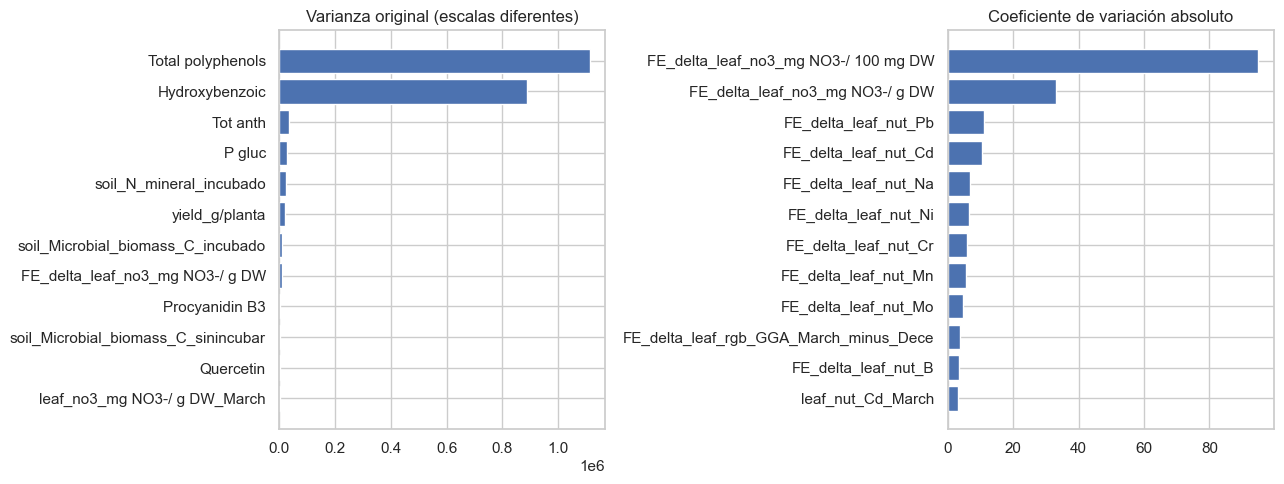

,Bloque,Variable,No_nulos,Ausentes,Varianza,CV_abs
91,Calidad nutricional / bioactivos,Total polyphenols,32,0,1.112725e+06,0.722107
89,Calidad nutricional / bioactivos,Hydroxybenzoic,32,0,8.887592e+05,0.748424
95,Calidad nutricional / bioactivos,Tot anth,29,3,3.340821e+04,0.873730
92,Calidad nutricional / bioactivos,P gluc,29,3,2.846183e+04,0.867519
10,Suelo,soil_N_mineral_incubado,32,0,2.372646e+04,0.447963
67,Producción,yield_g/planta,32,0,2.138683e+04,0.429508
5,Suelo,soil_Microbial_biomass_C_incubado,32,0,8.939059e+03,0.670303
36,Hoja / nutrición,FE_delta_leaf_no3_mg NO3-/ g DW,32,0,8.481488e+03,32.987090
76,Calidad nutricional / bioactivos,Procyanidin B3,32,0,4.566077e+03,0.842071
4,Suelo,soil_Microbial_biomass_C_sinincubar,32,0,3.747872e+03,0.622299


In [8]:
# Inventario de variables científicas y calidad
SCI_BLOCKS = {
    'Suelo': soil_fe,
    'Hoja / nutrición': leaf_fe,
    'Hoja / RGB': rgb_fe,
    'Producción': [c for c in production_cols if c in work.columns],
    'Calidad fisicoquímica': [c for c in physchem_cols if c in work.columns],
    'Calidad nutricional / bioactivos': [c for c in nutritional_cols if c in work.columns],
}
science_columns = list(dict.fromkeys(c for v in SCI_BLOCKS.values() for c in v))
science_catalog = pd.DataFrame([
    {'Bloque':block,'Variable':col,'No_nulos':int(work[col].notna().sum()),
     'Ausentes':int(work[col].isna().sum()), 'Varianza':float(work[col].var())}
    for block, cols in SCI_BLOCKS.items() for col in cols
])
display(science_catalog.groupby('Bloque',as_index=False).agg(Variables=('Variable','size'),
    Ausentes=('Ausentes','sum')))
science_catalog.to_csv(OUT/'catalogo_cientifico_multibloque.csv',index=False)
# Variación descriptiva: comparar variables mediante CV (sin unidades), solo si media != 0.
variability = science_catalog.copy()
means = {c:float(work[c].mean()) for c in science_columns}
variability['CV_abs'] = variability.apply(lambda r: np.sqrt(max(r['Varianza'],0))/abs(means[r['Variable']])
    if np.isfinite(means[r['Variable']]) and abs(means[r['Variable']])>1e-9 else np.nan,axis=1)
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax, metric, ttl in zip(axs,['Varianza','CV_abs'],['Varianza original (escalas diferentes)','Coeficiente de variación absoluto']):
    z=variability.replace([np.inf,-np.inf],np.nan).dropna(subset=[metric]).nlargest(12,metric)
    ax.barh(z['Variable'].str.slice(0,38),z[metric]);ax.invert_yaxis();ax.set_title(ttl)
plt.tight_layout();plt.savefig(FIG/'faseA_variabilidad.png',dpi=160);plt.show()
display(variability.sort_values('Varianza',ascending=False).head(15))

### Interpretación de la Fase A
Completar con las salidas reales: ¿qué bloques presentan ausencias?, ¿qué mediciones tienen escalas distintas?, ¿hay variables constantes? No seleccionar por varianza original sin estandarizar.

## FASE B — Correlaciones integrales y significancia exploratoria
La matriz reúne suelo, hoja, RGB, producción, calidad fisicoquímica y bioactivos **alineados por claves**. Se calcula Spearman por pares con n disponible y ajuste FDR; con 32 filas y suelo compartido por parcela, los valores p son **exploratorios**, no evidencia confirmatoria. No se seleccionan predictores para rendimiento usando resultados del fruto.

Variables en matriz científica: 34


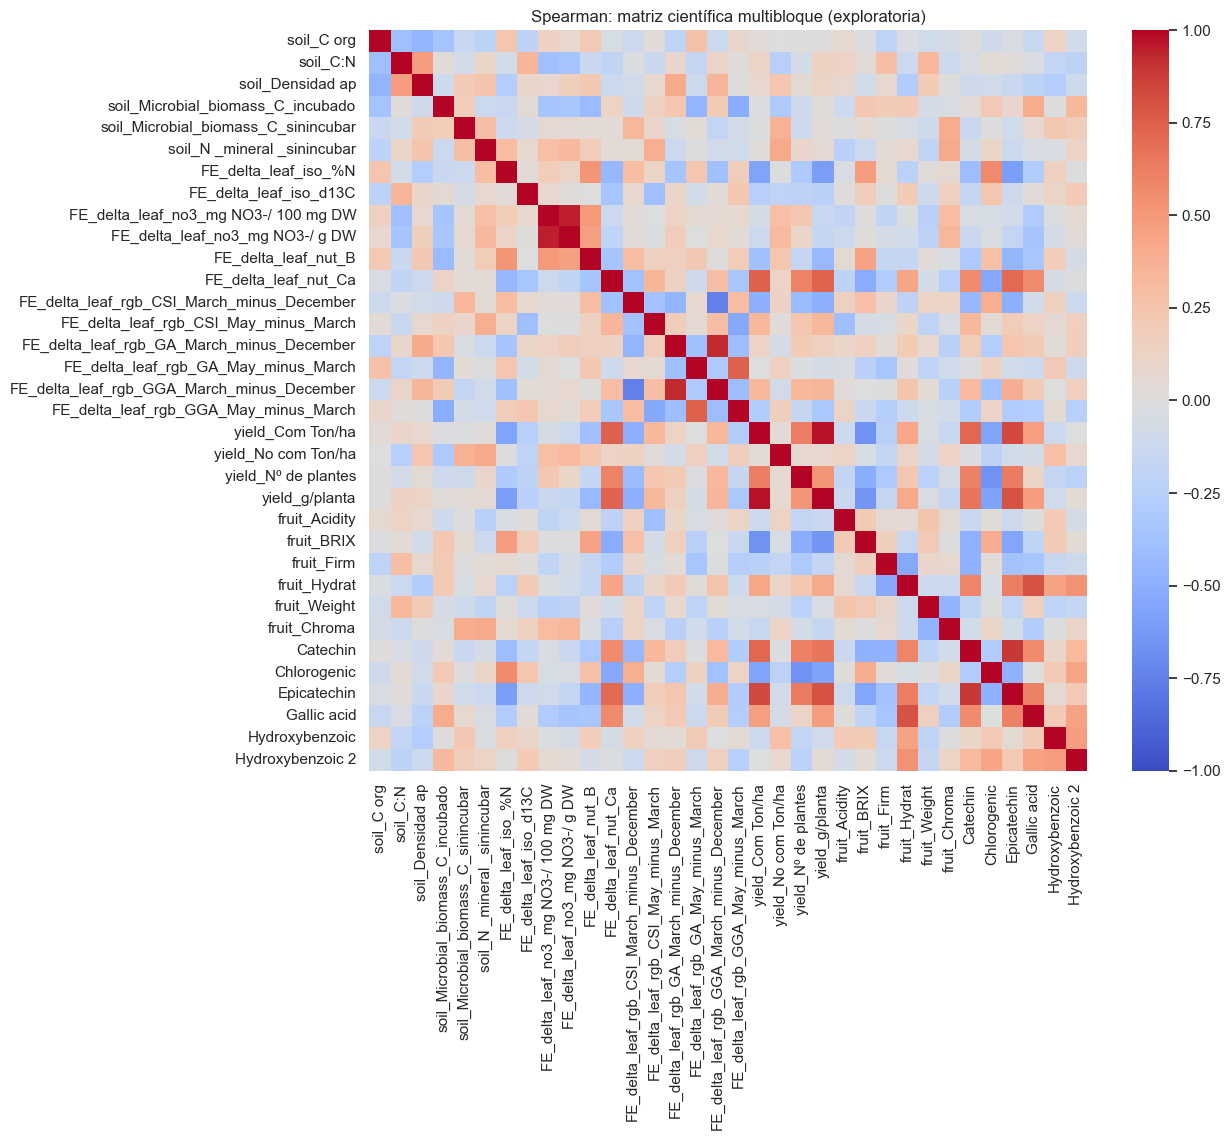

,Variable_1,Bloque_1,Variable_2,Bloque_2,n,rho,p,q_FDR
404,yield_Com Ton/ha,Producción,Epicatechin,Calidad nutricional / bioactivos,32,0.828446,4.816612e-09,0.000002
465,fruit_Hydrat,Calidad fisicoquímica,Gallic acid,Calidad nutricional / bioactivos,32,0.802256,3.365126e-08,0.000007
440,yield_g/planta,Producción,Epicatechin,Calidad nutricional / bioactivos,32,0.798387,4.376700e-08,0.000007
284,FE_delta_leaf_nut_Ca,Hoja / nutrición,yield_Com Ton/ha,Producción,32,0.744135,1.051036e-06,0.000126
287,FE_delta_leaf_nut_Ca,Hoja / nutrición,yield_g/planta,Producción,32,0.738270,1.413846e-06,0.000136
402,yield_Com Ton/ha,Producción,Catechin,Calidad nutricional / bioactivos,32,0.721041,3.235873e-06,0.000259
296,FE_delta_leaf_nut_Ca,Hoja / nutrición,Epicatechin,Calidad nutricional / bioactivos,32,0.711510,4.986816e-06,0.000342
397,yield_Com Ton/ha,Producción,fruit_BRIX,Calidad fisicoquímica,32,-0.670581,2.674351e-05,0.001426
427,yield_Nº de plantes,Producción,Chlorogenic,Calidad nutricional / bioactivos,32,-0.670865,2.645758e-05,0.001426
438,yield_g/planta,Producción,Catechin,Calidad nutricional / bioactivos,32,0.665323,3.257297e-05,0.001564


In [9]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
# Evitar calcular miles de pares indistinguibles: conservar hasta 6 variables
# representativas por bloque, elegidas por cobertura y variación estandarizada,
# SIN utilizar la variable objetivo para decidir.
representative={}
for block, cols in SCI_BLOCKS.items():
    candidates=[c for c in cols if work[c].notna().sum()>=12 and work[c].nunique(dropna=True)>2]
    representative[block]=sorted(candidates,key=lambda c:(-work[c].notna().sum(),c))[:6]
scientific_subset=list(dict.fromkeys(c for v in representative.values() for c in v))
print('Variables en matriz científica:',len(scientific_subset))
if len(scientific_subset)>=2:
    corr=work[scientific_subset].corr(method='spearman',min_periods=8)
    corr.to_csv(OUT/'correlaciones_multibloque.csv')
    fig,ax=plt.subplots(figsize=(max(9,len(corr)*.38),max(7,len(corr)*.34)))
    sns.heatmap(corr,center=0,cmap='coolwarm',vmin=-1,vmax=1,ax=ax)
    ax.set_title('Spearman: matriz científica multibloque (exploratoria)')
    plt.tight_layout();plt.savefig(FIG/'faseB_correlaciones.png',dpi=160);plt.show()
    col_block={c:b for b,cols in representative.items() for c in cols}
    assoc=[]
    for i,a in enumerate(scientific_subset):
        for b in scientific_subset[i+1:]:
            if col_block[a]==col_block[b]:continue
            valid=work[[a,b]].dropna()
            if len(valid)<8 or valid[a].nunique()<3 or valid[b].nunique()<3:continue
            rho,p=spearmanr(valid[a],valid[b])
            if np.isfinite(p):assoc.append({'Variable_1':a,'Bloque_1':col_block[a],
                'Variable_2':b,'Bloque_2':col_block[b],'n':len(valid),'rho':rho,'p':p})
    associations=pd.DataFrame(assoc)
    if not associations.empty:
        associations['q_FDR']=multipletests(associations['p'],method='fdr_bh')[1]
        associations=associations.sort_values('q_FDR')
        display(associations.head(25))
        associations.to_csv(OUT/'asociaciones_multibloque_FDR.csv',index=False)
else:
    corr=pd.DataFrame();associations=pd.DataFrame()
    print('No hay variables suficientes para la matriz científica.')

### Interpretación de la Fase B
Indicar asociaciones entre bloques, tamaños muestrales y valores q; distinguir significancia exploratoria de efecto causal. Evitar concluir que no existe relación solo porque no sobreviva al ajuste FDR.

## FASE C — PCA integral descriptivo
Se utiliza una selección de variables representativas de **todos los bloques** y escalamiento por bloque para que suelo, hoja y fruto contribuyan de forma comparable. El PCA **no se incorpora como predictor de rendimiento**, porque incluye resultados del fruto. No es necesario que todas las correlaciones sean significativas para explorar el PCA.

,PC,Varianza,Acumulada
0,1,0.252144,0.252144
1,2,0.120432,0.372577
2,3,0.107394,0.479971
3,4,0.083769,0.563739
4,5,0.064476,0.628215
5,6,0.055422,0.683637
6,7,0.054449,0.738087
7,8,0.049626,0.787712
8,9,0.035477,0.823190
9,10,0.028404,0.851594


,PC1,PC2
soil_C org,-0.024507,0.038499
soil_C:N,-0.032073,-0.096313
soil_Densidad ap,-0.018063,-0.131093
soil_Microbial_biomass_C_incubado,0.060557,0.015915
soil_Microbial_biomass_C_sinincubar,0.023482,0.167079
soil_N _mineral _sinincubar,0.007823,0.074123
FE_delta_leaf_iso_%N,-0.186577,0.175181
FE_delta_leaf_iso_d13C,-0.091475,0.080805
FE_delta_leaf_no3_mg NO3-/ 100 mg DW,-0.072660,0.028918
FE_delta_leaf_no3_mg NO3-/ g DW,-0.087310,0.028292


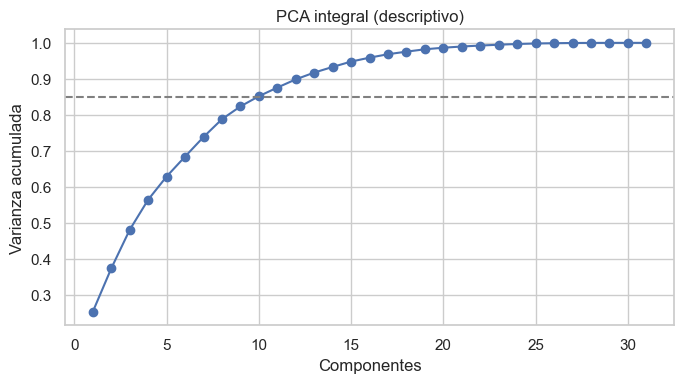

In [10]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
if len(scientific_subset)>=3:
    from sklearn.compose import ColumnTransformer
    # Mediana y escalado; ponderación 1/sqrt(numero de variables por bloque).
    sci_matrix=pd.DataFrame(index=work.index)
    for block, cols in representative.items():
        if not cols:continue
        part=SimpleImputer(strategy='median').fit_transform(work[cols])
        part=StandardScaler().fit_transform(part)/np.sqrt(len(cols))
        for j,c in enumerate(cols):sci_matrix[c]=part[:,j]
    max_comp=min(len(sci_matrix)-1,sci_matrix.shape[1])
    pca_science=PCA(n_components=max_comp).fit(sci_matrix)
    explained=np.cumsum(pca_science.explained_variance_ratio_)
    pca_science_report=pd.DataFrame({'PC':np.arange(1,max_comp+1),
        'Varianza':pca_science.explained_variance_ratio_,'Acumulada':explained})
    pca_science_loadings=pd.DataFrame(pca_science.components_.T,index=sci_matrix.columns,
        columns=[f'PC{i}' for i in range(1,max_comp+1)])
    display(pca_science_report.head(15))
    display(pca_science_loadings[['PC1','PC2']].head(25))
    pca_science_report.to_csv(OUT/'pca_integral_varianza.csv',index=False)
    pca_science_loadings.to_csv(OUT/'pca_integral_cargas.csv')
    fig,ax=plt.subplots(figsize=(7,4));ax.plot(np.arange(1,max_comp+1),explained,marker='o')
    ax.axhline(.85,color='gray',linestyle='--');ax.set(xlabel='Componentes',ylabel='Varianza acumulada',title='PCA integral (descriptivo)')
    plt.tight_layout();plt.savefig(FIG/'faseC_pca_integral.png',dpi=160);plt.show()
else:
    pca_science_report=pd.DataFrame();pca_science_loadings=pd.DataFrame()

### Interpretación de la Fase C
Describir varianza explicada, cargas principales y patrones de suelo–hoja–fruto; no interpretar PCA como una prueba de causalidad o significancia.

## FASE D — Diferencias entre cultivar y tratamiento
Se presentan medias por combinación y un contraste exploratorio. Para inferencia formal se requieren modelos mixtos o métodos que representen explícitamente el emparejamiento Donna–Dream por parcela; el contraste simple no es confirmatorio.

In [11]:
# Descriptivos multirrespuesta y contrastes exploratorios por cultivar
response_cols=list(dict.fromkeys(c for b in ['Producción','Calidad fisicoquímica','Calidad nutricional / bioactivos'] for c in SCI_BLOCKS[b]))
response_cols=[c for c in response_cols if work[c].notna().sum()>=12]
descriptive=work.groupby(['Treatment_name','Cultivar'],observed=True)[response_cols].agg(['mean','std','count'])
display(descriptive.iloc[:,:min(12,descriptive.shape[1])])
descriptive.to_csv(OUT/'descriptivos_tratamiento_cultivar.csv')
# ANOVA exploratorio por outcome: p-values no confirmatorios sin modelo jerárquico.
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
anova_rows=[]
for outcome in response_cols:
    dat=work[['Treatment_name','Cultivar',outcome]].dropna().rename(columns={outcome:'respuesta'})
    if len(dat)<20 or dat['respuesta'].nunique()<4:continue
    try:
        fit=smf.ols('respuesta ~ C(Treatment_name)*C(Cultivar)',data=dat).fit()
        table=anova_lm(fit,typ=2)
        for effect in table.index:
            if effect!='Residual':anova_rows.append({'Outcome':outcome,'Efecto':effect,
                'F':table.loc[effect,'F'],'p_exploratorio':table.loc[effect,'PR(>F)']})
    except (ValueError, np.linalg.LinAlgError):continue
anova_exploratory=pd.DataFrame(anova_rows)
if not anova_exploratory.empty:
    display(anova_exploratory.sort_values('p_exploratorio').head(25))
    anova_exploratory.to_csv(OUT/'anova_exploratoria_no_confirmatoria.csv',index=False)

yield_Com Ton/ha                 yield_No com Ton/ha                 yield_Nº de plantes                 yield_g/planta                 
                                    mean       std count                mean       std count                mean       std count           mean        std count
Treatment_name Cultivar                                                                                                                                         
Compost        Donna            7.791556  0.400582     4            0.877111  0.153611     4               18.75  0.500000     4     468.120614  35.059779     4
               Dream            3.404667  0.325458     4            1.032222  0.313443     4               15.75  0.957427     4     242.820404   8.895893     4
N-rich         Donna            7.271111  1.044682     4            0.956444  0.374674     4               18.25  0.500000     4     448.328947  65.147609     4
               Dream            2.624000  0.325645     4            1.000667  0.366424     4               17.00  0.816497     4     174.342525  26.783781     4
RCW-HD         Donna            7.816667  0.970270     4            1.237333  0.313807     4               18.25  0.500000     4     482.032164  61.152622     4
               Dream            2.629556  0.629108     4            0.850222  0.145735     4               17.75  0.500000     4     166.330065  37.492298     4
RCW-LD         Donna            8.001556  1.285571     4            1.121333  0.245677     4               18.00  0.000000     4     500.097222  80.348180     4
               Dream            3.454889  0.860182     4            1.000444  0.233438     4               16.00  1.414214     4     241.835741  47.727996     4

,Outcome,Efecto,F,p_exploratorio
1,yield_Com Ton/ha,C(Cultivar),271.279656,1.393112e-14
10,yield_g/planta,C(Cultivar),228.669456,9.102252e-14
91,Cyan,C(Cultivar),225.228940,1.065411e-12
94,Tot anth,C(Cultivar),219.649298,1.356642e-12
85,P gluc,C(Cultivar),213.625181,1.772367e-12
55,Rutin,C(Cultivar),167.583750,2.560020e-12
46,K-rutinoside,C(Cultivar),136.512666,2.167758e-11
88,P rut,C(Cultivar),119.025630,4.128514e-10
7,yield_Nº de plantes,C(Cultivar),39.763636,1.614062e-06
70,Epicatechin,C(Cultivar),33.794145,5.402141e-06


### Interpretación de la Fase D
Reportar diferencias descriptivas por cultivar y tratamiento. Los ANOVA simples son un diagnóstico preliminar, **no** sustituyen un modelo mixto con estructura de parcela ni el contraste de hipótesis de el estudio.

## FASE E — Auditoría 2022 frente a 2023
La existencia de filas de suelo en 2022 no implica disponer de las mismas mediciones de hoja, producción y calidad. La comparación entre años solo será válida cuando se aporten fuentes equivalentes y claves de año/parcelas verificadas.

In [12]:
years_soil=pd.to_numeric(soil_raw['Year'],errors='coerce').value_counts(dropna=False).sort_index()
year_audit=years_soil.rename_axis('Anio').reset_index(name='Filas_suelo')
display(year_audit)
year_audit.to_csv(OUT/'auditoria_anios_suelo.csv',index=False)
print('No se ha fusionado 2022 con 2023: falta verificar la cobertura de los otros bloques por año.')

,Anio,Filas_suelo
0,2022,16
1,2023,16


No se ha fusionado 2022 con 2023: falta verificar la cobertura de los otros bloques por año.


In [13]:
# Split por parcela para evitar que información compartida de suelo aparezca en train y test.
from sklearn.model_selection import GroupShuffleSplit

split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
itr,ite=next(split.split(work, groups=work['Parcel_ID']))
tr=work.iloc[itr].copy(); te=work.iloc[ite].copy()

assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
print('Entrenamiento:',tr.shape,'| Prueba:',te.shape)
print('Parcelas train/test:',tr.Parcel_ID.nunique(),te.Parcel_ID.nunique())
print('Overlap de parcelas:',set(tr.Parcel_ID)&set(te.Parcel_ID))
print('Parcelas test:',sorted(te.Parcel_ID.unique()))


Entrenamiento: (24, 103) | Prueba: (8, 103)
Parcelas train/test: 12 4
Overlap de parcelas: set()
Parcelas test: ['T1_R4', 'T3_R3', 'T4_R2', 'T4_R3']


Tarea: regresión | objetivo: yield_g/planta
Train/test: 24 8  | parcelas: 12 4
Predictores numéricos: 64  | categóricos: ['Treatment_name', 'Cultivar']
Faltantes en X train: 0
Duplicados de clave: 0
Objetivo (train):


,yield_g/planta
count,24.000000
mean,343.323458
std,151.163199
min,126.055556
25%,198.947917
50%,338.576797
75%,465.962719
max,595.722222


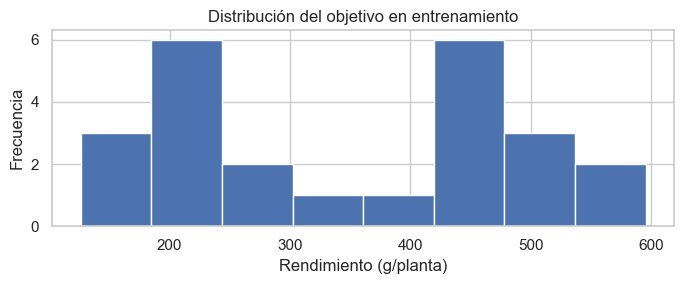

Atípicos IQR (objetivo, train): 0


In [14]:
TARGET = 'yield_g/planta'
assert TARGET in work.columns, f'Objetivo ausente: {TARGET}'
assert not work[['Cultivar','Treatment','Replicate']].duplicated().any()
assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
PRED_NUM = list(X_fe_cols)
PRED_CAT = ['Treatment_name', 'Cultivar']
PREDICTORS = PRED_NUM + PRED_CAT
assert TARGET not in PREDICTORS
train_data = tr.loc[tr[TARGET].notna()].copy()
test_data = te.loc[te[TARGET].notna()].copy()
print('Tarea: regresión | objetivo:', TARGET)
print('Train/test:', len(train_data), len(test_data), ' | parcelas:',train_data.Parcel_ID.nunique(),test_data.Parcel_ID.nunique())
print('Predictores numéricos:',len(PRED_NUM),' | categóricos:',PRED_CAT)
print('Faltantes en X train:',int(train_data[PREDICTORS].isna().sum().sum()))
print('Duplicados de clave:',int(work.duplicated(['Cultivar','Treatment','Replicate']).sum()))
print('Objetivo (train):');display(train_data[TARGET].describe().to_frame())
fig,ax=plt.subplots(figsize=(7,3));ax.hist(train_data[TARGET],bins=8,edgecolor='white');ax.set(xlabel='Rendimiento (g/planta)',ylabel='Frecuencia',title='Distribución del objetivo en entrenamiento');plt.tight_layout();plt.show()
# Auditoría descriptiva de atípicos (sin eliminarlos).
q1,q3=train_data[TARGET].quantile([.25,.75]);iqr=q3-q1
print('Atípicos IQR (objetivo, train):',int(((train_data[TARGET]<q1-1.5*iqr)|(train_data[TARGET]>q3+1.5*iqr)).sum()))

## 2. Diseño de evaluación sin fuga de información

- **Train/test:** se conserva `GroupShuffleSplit` del Avance 4. Donna y Dream de una misma parcela nunca se separan entre entrenamiento y prueba.
- **Validación externa:** `GroupKFold(4)` sobre las parcelas del conjunto de entrenamiento. Todos los candidatos usan exactamente los mismos folds.
- **Validación interna:** `GroupKFold(3)` para optimización de hiperparámetros.
- **Selección supervisada de variables:** permanece dentro de cada `Pipeline`; no se seleccionan variables utilizando el holdout.
- **Preprocesamiento:** imputación mediana, estandarización y One-Hot Encoding se ajustan solo con el fold de entrenamiento.
- **Categorías conocidas por diseño:** los niveles de tratamiento y cultivar se declaran explícitamente, por lo que la ausencia temporal de un tratamiento en un fold no genera una categoría desconocida.
- **Métrica primaria:** RMSE en g/planta. Como métricas secundarias se reportan MAE, R², desviación del RMSE, RMSE de entrenamiento y tiempo de entrenamiento.
- **Holdout:** se consulta una sola vez, después de elegir el modelo final con validación cruzada.

Los gráficos ROC, matriz de confusión y Precision-Recall son propios de clasificación y **no aplican** a este problema de regresión continua.


In [15]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.exceptions import ConvergenceWarning
from time import perf_counter
import warnings

# Modificables; no cambiar después de consultar test.
CV_OUTER_FOLDS = 4
CV_INNER_FOLDS = 3
FEATURE_QUOTAS = (4,6,2)
HOLDOUT_EVAL = False  # ejecutar UNA sola vez después de fijar el diseño.

class ScientificSelector(BaseEstimator, TransformerMixin):
    def __init__(self, quotas=(4,6,2), numeric_cols=None, cat_cols=None):
        self.quotas=quotas;self.numeric_cols=numeric_cols;self.cat_cols=cat_cols
    def fit(self,X,y):
        selected=[]
        for prefix,k in zip(('soil','leaf','rgb'),self.quotas):
            if prefix=='soil':cols=[c for c in self.numeric_cols if c.startswith('soil_')]
            elif prefix=='rgb':cols=[c for c in self.numeric_cols if c.startswith(('leaf_rgb_','FE_delta_leaf_rgb_'))]
            else:cols=[c for c in self.numeric_cols if c.startswith(('leaf_','FE_delta_leaf_')) and not c.startswith(('leaf_rgb_','FE_delta_leaf_rgb_'))]
            cols=[c for c in cols if c in X.columns and X[c].notna().any()]
            if not cols or k==0:continue
            z=X[cols].apply(pd.to_numeric,errors='coerce');z=z.fillna(z.median())
            valid=[c for c in cols if z[c].notna().all() and z[c].nunique()>1]
            if not valid:continue
            with warnings.catch_warnings():
                warnings.simplefilter('ignore');scores,_=f_regression(z[valid],np.asarray(y).ravel())
            rank=pd.DataFrame({'feature':valid,'F':np.nan_to_num(scores,nan=-1,posinf=-1,neginf=-1)}).sort_values(['F','feature'],ascending=[False,True])
            selected+=rank.head(k).feature.tolist()
        self.selected_=list(dict.fromkeys(selected))
        if not self.selected_:raise ValueError('Sin predictores numéricos seleccionados.')
        return self
    def transform(self,X):return X.loc[:,self.selected_+self.cat_cols].copy()

def one_hot():
    try:
        return OneHotEncoder(categories=[TREATMENT_ORDER,['Donna','Dream']], drop=None, handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(categories=[TREATMENT_ORDER,['Donna','Dream']], drop=None, handle_unknown='ignore', sparse=False)

def pipeline_for(estimator):
    prep=ColumnTransformer([
        ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),make_column_selector(dtype_include=np.number)),
        ('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('ohe',one_hot())]),PRED_CAT)
    ],sparse_threshold=0)
    return Pipeline([('selector',ScientificSelector(quotas=FEATURE_QUOTAS,numeric_cols=PRED_NUM,cat_cols=PRED_CAT)),('prep',prep),('model',estimator)])

MODELS = {
 'Regresión lineal':LinearRegression(),
 'Ridge':Ridge(alpha=10.0),
 'Lasso':Lasso(alpha=1.0,max_iter=30000,random_state=SEED),
 'SVR':SVR(kernel='rbf',C=1.0,epsilon=0.1, gamma='scale'),
 'KNN':KNeighborsRegressor(n_neighbors=3,weights='uniform'),
 'Árbol de decisión':DecisionTreeRegressor(max_depth=2,min_samples_leaf=3,random_state=SEED),
}
X=train_data[PREDICTORS];y=train_data[TARGET].astype(float);groups=train_data.Parcel_ID
outer_cv=GroupKFold(n_splits=min(CV_OUTER_FOLDS,groups.nunique()))
scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'}
print('Algoritmos individuales:',list(MODELS))

Algoritmos individuales: ['Regresión lineal', 'Ridge', 'Lasso', 'SVR', 'KNN', 'Árbol de decisión']


## FASE F — Selección por bloques: Top 6, Top 8, Top 12, Top 16, Top 20 y completo
Se comparan representaciones de diferente tamaño mediante Ridge y validación agrupada por parcela. **Top 6 y Top 8 son controles de sensibilidad**; Top 12, Top 16 y Top 20 preservan una representación más amplia de suelo, hoja y RGB. La selección supervisada se reajusta en cada fold. La decisión final también considera cobertura científica, no solo el mínimo RMSE.

,Configuracion,RMSE_CV,RMSE_sd,MAE_CV,RMSE_train,Num_numericas,Gap_RMSE
0,Completo,56.695,17.846,46.787,13.643,64.0,43.052
3,Top 20,59.093,10.599,43.564,31.227,20.0,27.866
1,Top 12,61.112,3.362,49.095,37.620,12.0,23.492
4,Top 6,61.821,8.266,51.251,47.057,6.0,14.764
2,Top 16,63.968,1.878,47.637,34.639,16.0,29.329
5,Top 8,72.507,6.242,62.340,42.424,8.0,30.084


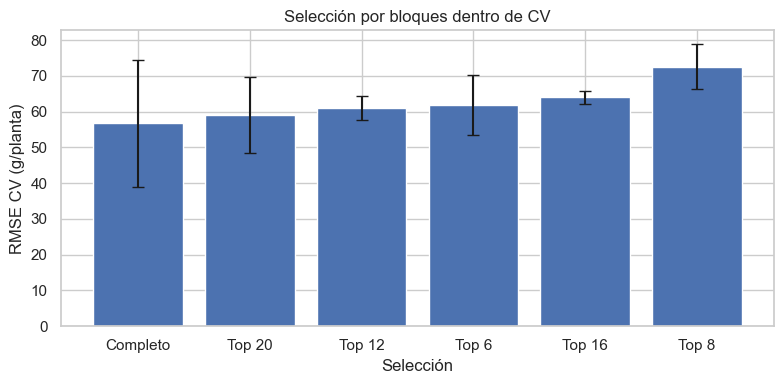

La configuracion diagnostica no impone la cuota final de los modelos.
Configuración seleccionada por CV para comparar modelos: Top 6
Cuotas activas: (2, 3, 1)
Advertencia: reutilizar CV para seleccionar cuotas y modelos puede introducir optimismo; no consultar holdout para decidir.


In [16]:
# Comparación de complejidad para el objetivo rendimiento, con Ridge fijo.
FEATURE_CANDIDATES={
    'Top 6':(2,3,1),
    'Top 8':(3,3,2),
    'Top 12':(4,6,2),
    'Top 16':(5,8,3),
    'Top 20':(6,10,4),
    'Completo':(999,999,999),
}
feature_rows=[]
for name,quotas in FEATURE_CANDIDATES.items():
    for fold,(ia,ib) in enumerate(outer_cv.split(X,y,groups),1):
        pipe=pipeline_for(Ridge(alpha=10.0))
        pipe.set_params(selector__quotas=quotas)
        pipe.fit(X.iloc[ia],y.iloc[ia])
        pr=pipe.predict(X.iloc[ib]);pt=pipe.predict(X.iloc[ia])
        feature_rows.append({'Configuracion':name,'Fold':fold,
            'Num_numericas':len(pipe.named_steps['selector'].selected_),
            'RMSE_CV':np.sqrt(mean_squared_error(y.iloc[ib],pr)),
            'RMSE_train':np.sqrt(mean_squared_error(y.iloc[ia],pt)),
            'MAE_CV':mean_absolute_error(y.iloc[ib],pr)})
feature_fold=pd.DataFrame(feature_rows)
feature_summary=feature_fold.groupby('Configuracion',as_index=False).agg(
    RMSE_CV=('RMSE_CV','mean'),RMSE_sd=('RMSE_CV','std'),
    MAE_CV=('MAE_CV','mean'),RMSE_train=('RMSE_train','mean'),
    Num_numericas=('Num_numericas','mean')).sort_values('RMSE_CV')
feature_summary['Gap_RMSE']=feature_summary.RMSE_CV-feature_summary.RMSE_train
display(feature_summary.round(3))
feature_summary.to_csv(OUT/'comparacion_cuotas_variables.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(feature_summary.Configuracion,feature_summary.RMSE_CV,
    yerr=feature_summary.RMSE_sd,capsize=4)
ax.set(xlabel='Selección',ylabel='RMSE CV (g/planta)',title='Selección por bloques dentro de CV')
plt.tight_layout();plt.savefig(FIG/'faseF_comparacion_cuotas.png',dpi=160);plt.show()
# Seleccion diagnostica por CV. La comparacion final preserva los tres bloques.
# Tolerancia: un error estándar de la mejor configuración; preferir menos variables.
leader=feature_summary.iloc[0]
threshold=leader['RMSE_CV'] + leader['RMSE_sd']/np.sqrt(CV_OUTER_FOLDS)
eligible=feature_summary.loc[feature_summary.RMSE_CV<=threshold].copy()
chosen=eligible.sort_values(['Num_numericas','RMSE_CV']).iloc[0]
SELECTED_FEATURE_CONFIG=str(chosen.Configuracion)
FEATURE_QUOTAS=FEATURE_CANDIDATES[SELECTED_FEATURE_CONFIG]
print('La configuracion diagnostica no impone la cuota final de los modelos.')
print('Configuración seleccionada por CV para comparar modelos:',SELECTED_FEATURE_CONFIG)
print('Cuotas activas:',FEATURE_QUOTAS)
print('Advertencia: reutilizar CV para seleccionar cuotas y modelos puede introducir optimismo; no consultar holdout para decidir.')

### Interpretación de la Fase F
Registrar qué cuota tiene menor RMSE, su desviación y brecha. Una diferencia pequeña no justifica preferir un conjunto mayor. La comparación es exploratoria; no usar el holdout para elegir cuotas.

## FASE G — 8. Construcción de modelos con interacciones
Se evalúan interacciones de segundo grado entre características seleccionadas. Las interacciones pueden representar relaciones conjuntas, pero con una muestra pequeña aumentan la dimensionalidad y el riesgo de sobreajuste. Se comparan modelos Ridge con y sin interacciones usando particiones agrupadas.

In [17]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression
# Transformación de segundo nivel aplicada después de la selección de base y preprocesamiento.
# Mantiene categorías codificadas; solo se interaccionan las numéricas seleccionadas.
class FoldInteractions(BaseEstimator, TransformerMixin):
    def __init__(self, max_terms=10, enabled=True):
        self.max_terms=max_terms;self.enabled=enabled
    def fit(self,X,y):
        X=np.asarray(X,dtype=float)
        self.n_input_=X.shape[1]
        # Las 6 primeras columnas son numéricas por la estructura ColumnTransformer.
        self.n_num_=min(6,self.n_input_-6)
        self.n_num_=max(0,self.n_num_)
        if not self.enabled or self.n_num_<2:
            self.selected_idx_=np.array([],dtype=int);return self
        self.poly_=PolynomialFeatures(degree=2,interaction_only=True,include_bias=False)
        z=self.poly_.fit_transform(X[:,:self.n_num_])[:,self.n_num_:]
        if z.shape[1]==0:
            self.selected_idx_=np.array([],dtype=int);return self
        # Elegir SOLO términos de interacción dentro del fold.
        k=min(self.max_terms,z.shape[1])
        self.kbest_=SelectKBest(score_func=f_regression,k=k).fit(z,y)
        self.selected_idx_=self.kbest_.get_support(indices=True)
        return self
    def transform(self,X):
        X=np.asarray(X,dtype=float)
        if not self.enabled or self.n_num_<2 or len(self.selected_idx_)==0:return X
        z=self.poly_.transform(X[:,:self.n_num_])[:,self.n_num_:]
        return np.column_stack([X,z[:,self.selected_idx_]])

# Interacciones base: 2 suelo + 3 hoja + 1 RGB (seis variables, todas seleccionadas por fold).
INTERACTION_QUOTAS=(2,3,1)
def interaction_pipeline(with_interactions):
    pipe=pipeline_for(Ridge(alpha=30.0))
    pipe.set_params(selector__quotas=INTERACTION_QUOTAS)
    return Pipeline([('selector',pipe.named_steps['selector']),
        ('prep',pipe.named_steps['prep']),
        ('interactions',FoldInteractions(max_terms=6,enabled=with_interactions)),
        ('scale_final',StandardScaler()),('model',Ridge(alpha=30.0))])

interaction_rows=[]
for label,enabled in [('Sin interacciones',False),('Con interacciones',True)]:
    for fold,(ia,ib) in enumerate(outer_cv.split(X,y,groups),1):
        pipe=interaction_pipeline(enabled)
        pipe.fit(X.iloc[ia],y.iloc[ia])
        pred=pipe.predict(X.iloc[ib]);train_pred=pipe.predict(X.iloc[ia])
        interaction_rows.append({'Modelo':label,'Fold':fold,
            'RMSE_CV':np.sqrt(mean_squared_error(y.iloc[ib],pred)),
            'MAE_CV':mean_absolute_error(y.iloc[ib],pred),
            'RMSE_train':np.sqrt(mean_squared_error(y.iloc[ia],train_pred)),
            'Num_interacciones':len(pipe.named_steps['interactions'].selected_idx_)})
interaction_folds=pd.DataFrame(interaction_rows)
interaction_summary=interaction_folds.groupby('Modelo',as_index=False).agg(
    RMSE_CV=('RMSE_CV','mean'),RMSE_sd=('RMSE_CV','std'),
    MAE_CV=('MAE_CV','mean'),RMSE_train=('RMSE_train','mean'),
    Num_interacciones=('Num_interacciones','mean')).sort_values('RMSE_CV')
interaction_summary['Gap_RMSE']=interaction_summary.RMSE_CV-interaction_summary.RMSE_train
display(interaction_summary.round(3))
interaction_summary.to_csv(OUT/'comparacion_interacciones.csv',index=False)

,Modelo,RMSE_CV,RMSE_sd,MAE_CV,RMSE_train,Num_interacciones,Gap_RMSE
1,Sin interacciones,62.340,13.223,49.847,53.550,0.0,8.791
0,Con interacciones,70.472,12.910,57.950,51.687,6.0,18.786


## FASE H — 9. Selección de interacciones con mayor poder predictivo
Se utiliza `SelectKBest` dentro de cada fold para evaluar términos de interacción. La decisión de conservarlos depende del error de validación, la brecha de generalización y la interpretabilidad; no se incorporan automáticamente a los modelos posteriores.

In [18]:
final_interaction_pipe=interaction_pipeline(True).fit(X,y)
sel=final_interaction_pipe.named_steps['selector'].selected_
terms=final_interaction_pipe.named_steps['interactions']
if terms.n_num_>=2 and len(terms.selected_idx_):
    labels=terms.poly_.get_feature_names_out(sel[:terms.n_num_])
    inter_labels=labels[terms.n_num_:]
    selected_interaction_names=[inter_labels[j] for j in terms.selected_idx_]
else:selected_interaction_names=[]
interaction_names=pd.DataFrame({'Interaccion_seleccionada':selected_interaction_names})
display(interaction_names)
interaction_names.to_csv(OUT/'interacciones_seleccionadas_entrenamiento.csv',index=False)
print('Interacciones reales seleccionadas:',len(selected_interaction_names))
print('Resultado de CV:',interaction_summary.iloc[0]['Modelo'])
print('Nota: no sustituir automáticamente el conjunto de variables del ensamble por este resultado.')

,Interaccion_seleccionada
0,soil_N_microbiano_incubado soil_Microbial_biom...
1,soil_Microbial_biomass_C_incubado FE_delta_lea...
2,leaf_nut_Mn_March FE_delta_leaf_nut_P
3,leaf_nut_Mn_March leaf_nut_P_March
4,FE_delta_leaf_nut_P leaf_nut_P_March
5,FE_delta_leaf_nut_P FE_delta_leaf_rgb_CSI_Marc...


Interacciones reales seleccionadas: 6
Resultado de CV: Sin interacciones
Nota: no sustituir automáticamente el conjunto de variables del ensamble por este resultado.


### Interpretación de las Fases G–H
Comparar RMSE, MAE y brecha. Si el modelo con interacciones no mejora la CV, **no** incorporarlas por obligación; la recomendación docente se cumple al probarlas y justificar la decisión. Confirmar con el estudio el significado agronómico de las interacciones elegidas.

## FASE I — Modelado de calidad fisicoquímica y nutricional
Se evalúan como objetivos separados **BRIX, acidez, vitamina C, actividad antioxidante, polifenoles y antocianinas**, siempre que las columnas y la cobertura lo permitan. Se comparan Dummy y Ridge con selección específica de variables por objetivo. **Suelo, hojas, RGB, tratamiento y cultivar** permanecen como predictores candidatos; los resultados del fruto no se utilizan para anticipar otros resultados del mismo fruto sin una justificación temporal. El análisis multibloque integral se conserva en las fases anteriores.

In [19]:
# ============================================================
# FASE I — Selección específica por cada objetivo científico
# ============================================================
import re
from sklearn.dummy import DummyRegressor

# Buscar en columnas de resultados (no en predictores).
# Se conservan todas las coincidencias de capacidad antioxidante
# porque pueden existir varios ensayos independientes.
QUALITY_PATTERNS = {
    'BRIX': r'BRIX|soluble.?solid|TSS',
    'Acidez': r'Acidity|Acidez|titratable',
    'Vitamina C': r'Vit.?C|Ascorb',
    'Antocianinas': r'Tot anth|Anthocyan',
    'Polifenoles': r'Total polyphen|Tot polyphen|Polyphenols',
    'Capacidad antioxidante': r'Antiox|DPPH|ABTS|FRAP|TEAC|ORAC',
}
QUALITY_QUOTAS = {
    'Top 6': (2,3,1),
    'Top 8': (3,3,2),
    'Top 12': (4,6,2),
    'Top 16': (5,8,3),
    'Top 20': (6,10,4),
}
# No se fuerza una columna única por familia; se registran coincidencias reales.
quality_catalog = []
for family, pattern in QUALITY_PATTERNS.items():
    found = [c for c in response_cols if re.search(pattern, c, flags=re.I)]
    if not found:
        quality_catalog.append({'Familia':family,'Columna':None,'Estado':'No encontrada'})
    for col in found:
        quality_catalog.append({'Familia':family,'Columna':col,
                                'Estado':'Disponible' if train_data[col].notna().sum() >= 12 else 'Cobertura insuficiente'})
quality_inventory = pd.DataFrame(quality_catalog)
display(quality_inventory)
quality_inventory.to_csv(OUT/'inventario_objetivos_calidad.csv', index=False)

quality_fold_rows = []
quality_selected_rows = []
for record in quality_catalog:
    label, target = record['Familia'], record['Columna']
    if target is None or record['Estado'] != 'Disponible':
        continue
    d = train_data.loc[train_data[target].notna()].copy()
    if len(d) < 12 or d.Parcel_ID.nunique() < 4 or d[target].nunique() < 4:
        continue
    xq, yq, gq = d[PREDICTORS], d[target].astype(float), d.Parcel_ID
    cvq = GroupKFold(n_splits=min(4, gq.nunique()))
    for cfg, quotas in [('Dummy', None)] + list(QUALITY_QUOTAS.items()):
        for fold, (ia, ib) in enumerate(cvq.split(xq, yq, gq), 1):
            if cfg == 'Dummy':
                model = DummyRegressor(strategy='mean')
            else:
                model = pipeline_for(Ridge(alpha=30.0))
                model.set_params(selector__quotas=quotas)
            model.fit(xq.iloc[ia], yq.iloc[ia])
            pred = np.asarray(model.predict(xq.iloc[ib])).ravel()
            quality_fold_rows.append({
                'Familia':label, 'Objetivo':target, 'Configuracion':cfg,
                'Fold':fold, 'n_train_objetivo':len(d),
                'RMSE':np.sqrt(mean_squared_error(yq.iloc[ib],pred)),
                'MAE':mean_absolute_error(yq.iloc[ib],pred),
                'n_variables':0 if cfg == 'Dummy' else len(model.named_steps['selector'].selected_),
            })

quality_folds = pd.DataFrame(quality_fold_rows)
if not quality_folds.empty:
    quality_report = (quality_folds.groupby(['Familia','Objetivo','Configuracion'],as_index=False)
                      .agg(RMSE_CV=('RMSE','mean'),RMSE_sd=('RMSE','std'),
                           MAE_CV=('MAE','mean'),Num_variables=('n_variables','mean'),
                           n_train=('n_train_objetivo','first')))
    # Mejor configuración de Ridge por objetivo; Dummy permanece como referencia.
    quality_best = (quality_report.loc[quality_report.Configuracion.ne('Dummy')]
                    .sort_values(['Objetivo','RMSE_CV','Num_variables'])
                    .groupby('Objetivo',as_index=False).first())
    dummy_quality = quality_report.loc[quality_report.Configuracion.eq('Dummy')].set_index('Objetivo')['RMSE_CV']
    quality_best['Mejora_Dummy_%'] = quality_best.apply(
        lambda r: 100*(dummy_quality[r.Objetivo]-r.RMSE_CV)/dummy_quality[r.Objetivo]
        if r.Objetivo in dummy_quality.index and dummy_quality[r.Objetivo]>0 else np.nan,axis=1)
    for r in quality_best.itertuples():
        quotas = QUALITY_QUOTAS[r.Configuracion]
        d = train_data.loc[train_data[r.Objetivo].notna()].copy()
        fitted = pipeline_for(Ridge(alpha=30.0)).set_params(selector__quotas=quotas)
        fitted.fit(d[PREDICTORS],d[r.Objetivo].astype(float))
        for col in fitted.named_steps['selector'].selected_:
            quality_selected_rows.append({'Familia':r.Familia,'Objetivo':r.Objetivo,
                                          'Configuracion':r.Configuracion,'Variable':col})
    quality_selected = pd.DataFrame(quality_selected_rows)
    display(quality_report.sort_values(['Familia','Objetivo','RMSE_CV']).round(3))
    display(quality_best.round(3))
    display(quality_selected)
    quality_folds.to_csv(OUT/'calidad_resultados_por_fold.csv',index=False)
    quality_report.to_csv(OUT/'calidad_comparacion_cuotas.csv',index=False)
    quality_best.to_csv(OUT/'calidad_mejor_configuracion_por_objetivo.csv',index=False)
    quality_selected.to_csv(OUT/'calidad_variables_seleccionadas_por_objetivo.csv',index=False)
else:
    quality_report=pd.DataFrame(); quality_best=pd.DataFrame(); quality_selected=pd.DataFrame()
    print('No hay objetivos de calidad con cobertura suficiente para CV agrupada.')

print('Importante: la selección por CV es exploratoria; no se ha consultado el holdout de calidad.')

,Familia,Columna,Estado
0,BRIX,fruit_BRIX,Disponible
1,Acidez,fruit_Acidity,Disponible
2,Vitamina C,Vit C,Disponible
3,Antocianinas,Tot anth,Disponible
4,Polifenoles,Total polyphenols,Disponible
5,Capacidad antioxidante,None,No encontrada


,Familia,Objetivo,Configuracion,RMSE_CV,RMSE_sd,MAE_CV,Num_variables,n_train
1,Acidez,fruit_Acidity,Top 12,0.054,0.026,0.047,12.0,24
4,Acidez,fruit_Acidity,Top 6,0.055,0.025,0.046,6.0,24
5,Acidez,fruit_Acidity,Top 8,0.056,0.027,0.047,8.0,24
2,Acidez,fruit_Acidity,Top 16,0.056,0.024,0.049,16.0,24
3,Acidez,fruit_Acidity,Top 20,0.057,0.024,0.049,20.0,24
0,Acidez,fruit_Acidity,Dummy,0.059,0.024,0.048,0.0,24
9,Antocianinas,Tot anth,Top 20,79.938,11.426,64.771,20.0,21
8,Antocianinas,Tot anth,Top 16,87.245,9.780,73.339,16.0,21
7,Antocianinas,Tot anth,Top 12,93.624,11.051,76.954,12.0,21
10,Antocianinas,Tot anth,Top 6,105.630,25.833,85.830,6.0,21


,Objetivo,Familia,Configuracion,RMSE_CV,RMSE_sd,MAE_CV,Num_variables,n_train,Mejora_Dummy_%
0,Tot anth,Antocianinas,Top 20,79.938,11.426,64.771,20.0,21,53.508
1,Total polyphenols,Polifenoles,Top 8,942.319,344.586,724.008,8.0,24,-21.389
2,Vit C,Vitamina C,Top 6,0.923,0.130,0.663,6.0,24,-7.257
3,fruit_Acidity,Acidez,Top 12,0.054,0.026,0.047,12.0,24,7.440
4,fruit_BRIX,BRIX,Top 12,0.626,0.213,0.551,12.0,24,16.685


,Familia,Objetivo,Configuracion,Variable
0,Antocianinas,Tot anth,Top 20,soil_Microbial_biomass_C_incubado
1,Antocianinas,Tot anth,Top 20,soil_Densidad ap
2,Antocianinas,Tot anth,Top 20,soil_N_microbiano_incubado
3,Antocianinas,Tot anth,Top 20,soil_N_mineral_incubado
4,Antocianinas,Tot anth,Top 20,soil_Microbial_biomass_C_sinincubar
5,Antocianinas,Tot anth,Top 20,soil_N_microbiano_sinincubar
6,Antocianinas,Tot anth,Top 20,leaf_no3_mg NO3-/ 100 mg DW_March
7,Antocianinas,Tot anth,Top 20,leaf_nut_Mn_March
8,Antocianinas,Tot anth,Top 20,leaf_no3_mg NO3-/ g DW_March
9,Antocianinas,Tot anth,Top 20,leaf_nut_P_March


Importante: la selección por CV es exploratoria; no se ha consultado el holdout de calidad.


### Interpretación de la Fase I

Revisar `inventario_objetivos_calidad.csv`, `calidad_comparacion_cuotas.csv` y `calidad_variables_seleccionadas_por_objetivo.csv`. Identificar qué indicadores de calidad están realmente disponibles y si cada modelo mejora a Dummy. **No extrapolar la selección de rendimiento a todos los bioactivos.** Una variable seleccionada para antocianinas no es necesariamente relevante para vitamina C. Los resultados deben discutirse con el estudio junto con los análisis multibloque, las unidades químicas y las limitaciones de muestra.

## 3. Comparación de modelos individuales y estrategias de ensamble
Se comparan seis regresores individuales (regresión lineal, Ridge, Lasso, SVR, KNN y árbol de decisión) y cinco alternativas de ensamble (Bagging, Random Forest, Extra Trees, Voting y Stacking), bajo validación agrupada. Ninguna familia se considera ganadora antes de evaluar los resultados. El mismo conjunto de características científicas candidatas se mantiene disponible para todos los modelos.

La comparación usa RMSE como métrica principal y reporta MAE, R², variabilidad entre folds, error de entrenamiento y tiempos. Las técnicas de ensamble se incorporan como alternativas, no como objetivo exclusivo.

In [20]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor, VotingRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance
import inspect

# Grillas idénticas a las usadas en Avance 4 para los dos mejores modelos individuales.
PARAM_GRIDS_INDIVIDUAL = {
    'KNN': {
        'model__n_neighbors':[2,3,4,5],
        'model__weights':['uniform','distance'],
        'model__p':[1,2],
        'selector__quotas':[(4,6,2),(5,8,3),(6,10,4)]
    },
    'Ridge': {
        'model__alpha':[0.1,1,3,10,30,100,300,1000],
        'selector__quotas':[(4,6,2),(5,8,3),(6,10,4)]
    }
}

BEST_PREVIOUS = ['KNN','Ridge']

# Espacios compactos: se optimiza complejidad sin inflar artificialmente la búsqueda con n≈24 en train.
ENSEMBLE_GRIDS = {
    'Bagging': {
        'n_estimators':[30,60],
        'max_samples':[10,12],
        'min_samples_leaf':[2],
        'selector_quotas':[(4,6,2),(5,8,3),(6,10,4)]
    },
    'Random Forest': {
        'n_estimators':[100,200],
        'max_depth':[2,3,4],
        'min_samples_leaf':[2,3,4],
        'max_features':[0.5,0.7,1.0],
        'selector_quotas':[(4,6,2),(5,8,3),(6,10,4)]
    },
    'Extra Trees': {
        'n_estimators':[60,120],
        'max_depth':[2,4],
        'min_samples_leaf':[2],
        'max_features':[0.7],
        'selector_quotas':[(4,6,2),(5,8,3),(6,10,4)]
    },
    'Voting KNN + Ridge': {
        'weights':[(1,1),(2,1),(1,2)]
    },
    'Stacking KNN + Ridge': {
        'meta_alpha':[1.0,10.0,100.0],
        'n_splits':[3]
    }
}


def tune_individual(name, X_fit, y_fit, groups_fit):
    """Optimiza KNN o Ridge respetando parcelas."""
    cv = GroupKFold(n_splits=min(CV_INNER_FOLDS, pd.Series(groups_fit).nunique()))
    search = GridSearchCV(
        pipeline_for(clone(MODELS[name])),
        PARAM_GRIDS_INDIVIDUAL[name],
        scoring='neg_root_mean_squared_error',
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score='raise'
    )
    start = perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        search.fit(X_fit, y_fit, groups=groups_fit)
    return search.best_estimator_, search.best_params_, -search.best_score_, perf_counter()-start


def pipeline_from_best(name, best_params):
    """Reconstruye KNN/Ridge con los parámetros óptimos de un fold."""
    if name == 'KNN':
        est = KNeighborsRegressor(
            n_neighbors=best_params['model__n_neighbors'],
            weights=best_params['model__weights'],
            p=best_params['model__p']
        )
    elif name == 'Ridge':
        est = Ridge(alpha=best_params['model__alpha'])
    else:
        raise KeyError(name)
    pipe = pipeline_for(est)
    pipe.set_params(selector__quotas=best_params['selector__quotas'])
    return pipe


class GroupStackingRegressor(BaseEstimator, RegressorMixin):
    """Stacking de KNN y Ridge con meta-modelo Ridge y OOF agrupado por parcela."""
    def __init__(self, knn_params=None, ridge_params=None, meta_alpha=10.0, n_splits=3):
        self.knn_params = knn_params
        self.ridge_params = ridge_params
        self.meta_alpha = meta_alpha
        self.n_splits = n_splits

    def _base_models(self):
        return [
            pipeline_from_best('KNN', self.knn_params),
            pipeline_from_best('Ridge', self.ridge_params)
        ]

    def fit(self, X, y, groups=None):
        if groups is None:
            raise ValueError('Stacking requiere groups=Parcel_ID para evitar fuga de información.')
        Xr = X.reset_index(drop=True)
        yr = pd.Series(np.asarray(y), dtype=float).reset_index(drop=True)
        gr = pd.Series(np.asarray(groups)).reset_index(drop=True)
        n_splits = min(self.n_splits, gr.nunique())
        cv = GroupKFold(n_splits=n_splits)
        oof = np.full((len(Xr), 2), np.nan)

        for a,b in cv.split(Xr, yr, gr):
            for j, est in enumerate(self._base_models()):
                est.fit(Xr.iloc[a], yr.iloc[a])
                oof[b,j] = np.asarray(est.predict(Xr.iloc[b])).ravel()

        if not np.isfinite(oof).all():
            raise ValueError('Stacking produjo predicciones OOF no finitas.')

        self.meta_ = Ridge(alpha=self.meta_alpha).fit(oof, yr)
        self.base_ = self._base_models()
        for est in self.base_:
            est.fit(Xr, yr)
        return self

    def predict(self, X):
        meta_X = np.column_stack([np.asarray(m.predict(X)).ravel() for m in self.base_])
        return self.meta_.predict(meta_X)


def make_bagging(n_estimators=50, max_samples=.8, min_samples_leaf=3):
    base = DecisionTreeRegressor(max_depth=3, min_samples_leaf=min_samples_leaf, random_state=SEED)
    kwargs = dict(n_estimators=n_estimators, max_samples=max_samples, random_state=SEED, n_jobs=-1)
    if 'estimator' in inspect.signature(BaggingRegressor).parameters:
        kwargs['estimator'] = base
    else:
        kwargs['base_estimator'] = base
    return BaggingRegressor(**kwargs)


def build_ensemble(name, params, knn_best, ridge_best):
    """Construye cada ensamble usando solo información del conjunto de entrenamiento correspondiente."""
    if name == 'Bagging':
        p = pipeline_for(make_bagging(params['n_estimators'], params['max_samples'], params['min_samples_leaf']))
        p.set_params(selector__quotas=params['selector_quotas'])
        return p
    if name == 'Random Forest':
        est = RandomForestRegressor(
            n_estimators=params['n_estimators'], max_depth=params['max_depth'],
            min_samples_leaf=params['min_samples_leaf'], max_features=params['max_features'],
            random_state=SEED, n_jobs=-1
        )
        p = pipeline_for(est); p.set_params(selector__quotas=params['selector_quotas']); return p
    if name == 'Extra Trees':
        est = ExtraTreesRegressor(
            n_estimators=params['n_estimators'], max_depth=params['max_depth'],
            min_samples_leaf=params['min_samples_leaf'], max_features=params['max_features'],
            random_state=SEED, n_jobs=-1
        )
        p = pipeline_for(est); p.set_params(selector__quotas=params['selector_quotas']); return p
    if name == 'Voting KNN + Ridge':
        return VotingRegressor(
            estimators=[
                ('knn', pipeline_from_best('KNN', knn_best)),
                ('ridge', pipeline_from_best('Ridge', ridge_best))
            ],
            weights=params['weights'], n_jobs=1
        )
    if name == 'Stacking KNN + Ridge':
        return GroupStackingRegressor(
            knn_params=knn_best, ridge_params=ridge_best,
            meta_alpha=params['meta_alpha'], n_splits=params['n_splits']
        )
    raise KeyError(name)


def fit_with_groups(estimator, name, X_fit, y_fit, groups_fit):
    if name == 'Stacking KNN + Ridge':
        estimator.fit(X_fit, y_fit, groups=groups_fit)
    else:
        estimator.fit(X_fit, y_fit)
    return estimator


# Presupuesto controlado: Random Forest tiene 162 combinaciones posibles,
# pero se prueban 30 seleccionadas reproduciblemente en cada entrenamiento interno.
# El muestreo usa una semilla fija; no utiliza los resultados del holdout.
RF_SEARCH_BUDGET = 30

def sampled_ensemble_grid(name):
    grid = list(ParameterGrid(ENSEMBLE_GRIDS[name]))
    if name != 'Random Forest' or len(grid) <= RF_SEARCH_BUDGET:
        return grid
    rng = np.random.default_rng(SEED)
    # Cobertura obligatoria de las tres cuotas de variables.
    mandatory=[]
    for q in [(4,6,2),(5,8,3),(6,10,4)]:
        matches=[i for i,p in enumerate(grid) if p['selector_quotas']==q]
        mandatory.append(int(rng.choice(matches)))
    remaining=[i for i in range(len(grid)) if i not in mandatory]
    extra=rng.choice(remaining, size=RF_SEARCH_BUDGET-len(mandatory), replace=False)
    return [grid[i] for i in mandatory+list(extra)]

def tune_ensemble(name, X_fit, y_fit, groups_fit, knn_best, ridge_best):
    """Grid manual con CV interna agrupada; devuelve modelo ajustado sobre todo X_fit."""
    cv = GroupKFold(n_splits=min(CV_INNER_FOLDS, pd.Series(groups_fit).nunique()))
    best_score = np.inf
    best_params = None
    start = perf_counter()

    for params in sampled_ensemble_grid(name):
        losses=[]
        for a,b in cv.split(X_fit, y_fit, groups_fit):
            est = build_ensemble(name, params, knn_best, ridge_best)
            est = fit_with_groups(est, name, X_fit.iloc[a], y_fit.iloc[a], groups_fit.iloc[a])
            pred = np.asarray(est.predict(X_fit.iloc[b])).ravel()
            losses.append(np.sqrt(mean_squared_error(y_fit.iloc[b], pred)))
        score = float(np.mean(losses))
        if score < best_score:
            best_score = score
            best_params = params

    fitted = build_ensemble(name, best_params, knn_best, ridge_best)
    fitted = fit_with_groups(fitted, name, X_fit, y_fit, groups_fit)
    return fitted, best_params, best_score, perf_counter()-start

print('Modelos individuales de Avance 4:', list(MODELS))
print('Mejores familias individuales usadas en Voting/Stacking:', BEST_PREVIOUS)
print('Ensambles:', list(ENSEMBLE_GRIDS))
print('Espacios completos:', {k:len(list(ParameterGrid(v))) for k,v in ENSEMBLE_GRIDS.items()})
print('Configuraciones evaluadas por búsqueda:', {k:len(sampled_ensemble_grid(k)) for k in ENSEMBLE_GRIDS})

Modelos individuales de Avance 4: ['Regresión lineal', 'Ridge', 'Lasso', 'SVR', 'KNN', 'Árbol de decisión']
Mejores familias individuales usadas en Voting/Stacking: ['KNN', 'Ridge']
Ensambles: ['Bagging', 'Random Forest', 'Extra Trees', 'Voting KNN + Ridge', 'Stacking KNN + Ridge']
Espacios completos: {'Bagging': 12, 'Random Forest': 162, 'Extra Trees': 12, 'Voting KNN + Ridge': 3, 'Stacking KNN + Ridge': 3}
Configuraciones evaluadas por búsqueda: {'Bagging': 12, 'Random Forest': 30, 'Extra Trees': 12, 'Voting KNN + Ridge': 3, 'Stacking KNN + Ridge': 3}


## 4. Comparación general y optimización de modelos
Primero se evalúan **todos los modelos individuales y ensambles** en condiciones comparables. Después se examinan las configuraciones de hiperparámetros y cuotas de variables de los candidatos. Las búsquedas de Bagging, Random Forest y Extra Trees incluyen Top 12, Top 16 y Top 20; Top 6 y Top 8 se conservan en la Fase F como análisis de sensibilidad, pero no se adoptan como modelo final integral.

Random Forest explora `max_depth` (2, 3, 4), `min_samples_leaf` (2, 3, 4), `max_features` (0.5, 0.7, 1.0) y `n_estimators` (100, 200), además de las tres cuotas multibloque. Se usa un presupuesto reproducible de 30 configuraciones por búsqueda interna y `GroupKFold`.

Las interacciones de las Fases G–H se conservan como experimento independiente. Como no mejoraron la validación de Ridge en el ensayo anterior, no se incorporan automáticamente a Random Forest. El conjunto de prueba ya se consultó en avances anteriores: cualquier métrica de prueba es **exploratoria y no una validación externa independiente**.

In [21]:
# Modelos a comparar: 6 individuales del Avance 4 + 5 ensambles.
INDIVIDUAL_NAMES = list(MODELS.keys())
ENSEMBLE_NAMES = list(ENSEMBLE_GRIDS.keys())
ALL_NAMES = INDIVIDUAL_NAMES + ENSEMBLE_NAMES

results_by_model = {name: [] for name in ALL_NAMES}
fold_rows = []
oof_predictions = {name: np.full(len(X), np.nan) for name in ALL_NAMES}

for fold, (idx_train, idx_val) in enumerate(outer_cv.split(X, y, groups), start=1):
    X_a, X_b = X.iloc[idx_train], X.iloc[idx_val]
    y_a, y_b = y.iloc[idx_train], y.iloc[idx_val]
    g_a = groups.iloc[idx_train]

    # Optimización de los dos mejores individuales de Avance 4 dentro del train externo.
    knn_fit, knn_params, knn_inner_rmse, knn_time = tune_individual('KNN', X_a, y_a, g_a)
    ridge_fit, ridge_params, ridge_inner_rmse, ridge_time = tune_individual('Ridge', X_a, y_a, g_a)

    # 1) Seis modelos individuales de la fase previa.
    for name in INDIVIDUAL_NAMES:
        start = perf_counter()
        if name == 'KNN':
            fitted = knn_fit; params = knn_params; tuning_time = knn_time
        elif name == 'Ridge':
            fitted = ridge_fit; params = ridge_params; tuning_time = ridge_time
        else:
            fitted = pipeline_for(clone(MODELS[name]))
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                fitted.fit(X_a, y_a)
            params = {'configuración':'Avance 4 sin optimización adicional'}
            tuning_time = perf_counter()-start

        pred_val = np.asarray(fitted.predict(X_b)).ravel()
        pred_train = np.asarray(fitted.predict(X_a)).ravel()
        rmse = np.sqrt(mean_squared_error(y_b, pred_val))
        mae = mean_absolute_error(y_b, pred_val)
        r2 = r2_score(y_b, pred_val) if y_b.nunique()>1 else np.nan
        rmse_train = np.sqrt(mean_squared_error(y_a, pred_train))
        oof_predictions[name][idx_val] = pred_val

        row = dict(Modelo=name, Tipo='Individual (Avance 4)', Estrategia='Individual', Fold=fold,
                   RMSE=rmse, MAE=mae, R2=r2, RMSE_train=rmse_train,
                   Tiempo_entrenamiento_s=tuning_time, Parametros=str(params))
        results_by_model[name].append(row); fold_rows.append(row)

    # 2) Ensambles. Voting/Stacking usan KNN y Ridge optimizados en este train externo.
    for name in ENSEMBLE_NAMES:
        fitted, params, inner_rmse, elapsed = tune_ensemble(
            name, X_a, y_a, g_a, knn_params, ridge_params
        )
        pred_val = np.asarray(fitted.predict(X_b)).ravel()
        pred_train = np.asarray(fitted.predict(X_a)).ravel()
        rmse = np.sqrt(mean_squared_error(y_b, pred_val))
        mae = mean_absolute_error(y_b, pred_val)
        r2 = r2_score(y_b, pred_val) if y_b.nunique()>1 else np.nan
        rmse_train = np.sqrt(mean_squared_error(y_a, pred_train))
        oof_predictions[name][idx_val] = pred_val

        strategy = 'Heterogéneo' if name in ['Voting KNN + Ridge','Stacking KNN + Ridge'] else 'Homogéneo'
        row = dict(Modelo=name, Tipo='Ensamble', Estrategia=strategy, Fold=fold,
                   RMSE=rmse, MAE=mae, R2=r2, RMSE_train=rmse_train,
                   Tiempo_entrenamiento_s=elapsed, Parametros=str(params))
        results_by_model[name].append(row); fold_rows.append(row)

# Resumen único solicitado por la rúbrica.
summary_rows=[]
for name in ALL_NAMES:
    d=pd.DataFrame(results_by_model[name])
    summary_rows.append({
        'Modelo':name,
        'Tipo':d['Tipo'].iloc[0],
        'Estrategia':d['Estrategia'].iloc[0],
        'RMSE_CV':d.RMSE.mean(),
        'RMSE_sd':d.RMSE.std(ddof=1),
        'MAE_CV':d.MAE.mean(),
        'R2_CV':d.R2.mean(),
        'RMSE_train':d.RMSE_train.mean(),
        'Gap_RMSE':d.RMSE.mean()-d.RMSE_train.mean(),
        'Tiempo_entrenamiento_s':d.Tiempo_entrenamiento_s.sum()
    })

comparison5 = pd.DataFrame(summary_rows).sort_values(['RMSE_CV','RMSE_sd']).reset_index(drop=True)
comparison5.insert(0, 'Posición', np.arange(1,len(comparison5)+1))

OUT5 = OUT / 'ensambles'
OUT5.mkdir(parents=True, exist_ok=True)
comparison5.to_csv(OUT5/'comparativa_modelos.csv', index=False)
pd.DataFrame(fold_rows).to_csv(OUT5/'resultados_por_fold.csv', index=False)

display(comparison5.round(3))


,Posición,Modelo,Tipo,Estrategia,RMSE_CV,RMSE_sd,MAE_CV,R2_CV,RMSE_train,Gap_RMSE,Tiempo_entrenamiento_s
0,1,Random Forest,Ensamble,Homogéneo,56.764,13.285,43.657,0.849,31.586,25.178,95.092
1,2,Extra Trees,Ensamble,Homogéneo,58.888,12.110,45.582,0.833,31.232,27.656,22.058
2,3,Ridge,Individual (Avance 4),Individual,60.429,10.893,45.856,0.831,30.127,30.302,6.489
3,4,Voting KNN + Ridge,Ensamble,Heterogéneo,60.547,14.825,47.119,0.829,38.493,22.054,3.679
4,5,Stacking KNN + Ridge,Ensamble,Heterogéneo,61.490,15.300,49.053,0.822,39.481,22.010,15.184
5,6,KNN,Individual (Avance 4),Individual,65.218,18.600,52.803,0.798,47.368,17.850,19.280
6,7,Bagging,Ensamble,Homogéneo,65.454,11.206,51.019,0.802,41.811,23.643,18.860
7,8,Lasso,Individual (Avance 4),Individual,70.001,14.495,57.807,0.774,27.931,42.070,0.282
8,9,Árbol de decisión,Individual (Avance 4),Individual,73.520,7.975,59.381,0.737,37.906,35.614,0.187
9,10,Regresión lineal,Individual (Avance 4),Individual,103.922,19.032,91.737,0.480,23.030,80.892,0.411


### 4.1. Auditoría de cuotas y parámetros por fold
Se documentan las cuotas multibloque y los hiperparámetros elegidos por cada fold de Random Forest. La auditoría complementa la tabla general y no reemplaza la comparación entre todos los modelos. No se considera una cuota universalmente óptima.

In [22]:
# ============================================================
# 4.1 Auditoría de cuotas y parámetros elegidos para Random Forest
# ============================================================
import ast
rf_folds = pd.DataFrame(results_by_model['Random Forest'])
rf_details = []
for row in rf_folds.itertuples():
    p = ast.literal_eval(row.Parametros)
    rf_details.append({
        'Fold':row.Fold, 'Configuracion':{(4,6,2):'Top 12',(5,8,3):'Top 16',(6,10,4):'Top 20'}.get(tuple(p['selector_quotas']),'Otra'),
        'Num_numericas':sum(p['selector_quotas']),
        'max_depth':p['max_depth'], 'min_samples_leaf':p['min_samples_leaf'],
        'max_features':p['max_features'], 'n_estimators':p['n_estimators'],
        'RMSE_CV':row.RMSE, 'RMSE_train':row.RMSE_train,
        'MAE_CV':row.MAE,
    })
rf_audit = pd.DataFrame(rf_details)
display(rf_audit.round(3))
display(rf_audit['Configuracion'].value_counts().rename_axis('Cuota').to_frame('Folds_seleccionada'))
rf_audit.to_csv(OUT5/'rf_cuotas_y_parametros_por_fold.csv',index=False)
print('Las cuotas se seleccionan de nuevo en cada fold: no existe un Top universal.')

,Fold,Configuracion,Num_numericas,max_depth,min_samples_leaf,max_features,n_estimators,RMSE_CV,RMSE_train,MAE_CV
0,1,Top 16,16,2,2,0.7,200,43.695,30.711,34.302
1,2,Top 16,16,2,2,1.0,100,72.477,33.072,53.230
2,3,Top 16,16,4,2,0.7,200,62.800,30.458,52.607
3,4,Top 20,20,3,2,0.5,200,48.085,32.105,34.489


,Folds_seleccionada
Cuota,
Top 16,3
Top 20,1


Las cuotas se seleccionan de nuevo en cada fold: no existe un Top universal.


## 5. Selección del modelo final y evaluación exploratoria
La selección se fundamenta en RMSE de validación, estabilidad entre parcelas, complejidad y representación científica. Para el objetivo de rendimiento, los candidatos finales deben preservar variables de **suelo, nutrición foliar y RGB**; las configuraciones compactas de sensibilidad se reportan por separado. La prueba reutilizada solo sirve como auditoría exploratoria, no como validación independiente.

In [24]:

# ============================================================
# 5. SELECCION, OPTIMIZACION Y EVALUACION DEL MODELO FINAL
# ============================================================

from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 5.1 CONFIGURACIONES CIENTIFICAS PERMITIDAS
# ------------------------------------------------------------

# Se conserva representacion de:
# - Suelo
# - Nutricion foliar
# - Indicadores RGB
#
# Las variables de calidad del fruto se analizan mediante
# objetivos independientes para evitar fuga de informacion.

MULTIBLOCK_QUOTAS = {
    "Top 12": (4, 6, 2),
    "Top 16": (5, 8, 3),
    "Top 20": (6, 10, 4)
}

ALLOWED_QUOTAS = set(MULTIBLOCK_QUOTAS.values())

# El espacio de busqueda de tune_individual y tune_ensemble
# debe restringirse a estas cuotas ANTES del ajuste.


# ------------------------------------------------------------
# 5.2 SELECCION DEL MEJOR MODELO
# ------------------------------------------------------------

comparison5 = comparison5.copy()

required_cols = [
    "Modelo",
    "RMSE_CV",
    "RMSE_sd",
    "Tiempo_entrenamiento_s"
]

missing_cols = [
    c for c in required_cols
    if c not in comparison5.columns
]

if missing_cols:
    raise ValueError(
        f"Faltan columnas en comparison5: {missing_cols}"
    )

comparison5 = comparison5.dropna(
    subset=["RMSE_CV", "RMSE_sd"]
)

if comparison5.empty:
    raise ValueError(
        "No existen modelos validos para seleccionar."
    )

comparison5 = comparison5.sort_values(
    ["RMSE_CV", "RMSE_sd", "Tiempo_entrenamiento_s"]
).reset_index(drop=True)

best_rmse = comparison5["RMSE_CV"].min()

comparison5["Diferencia_vs_mejor_%"] = (
    100 * (
        comparison5["RMSE_CV"] / best_rmse - 1
    )
)

# Modelos dentro del 5% del menor RMSE.
competitive = comparison5.loc[
    comparison5["Diferencia_vs_mejor_%"] <= 5
].copy()

# Prioridad: menor RMSE, estabilidad y tiempo.
selected_row = competitive.sort_values(
    [
        "RMSE_CV",
        "RMSE_sd",
        "Tiempo_entrenamiento_s"
    ]
).iloc[0]

winner = selected_row["Modelo"]

print("=" * 60)
print("SELECCION DEL MODELO FINAL")
print("=" * 60)

print(
    "Mejor RMSE CV:",
    round(best_rmse, 3)
)

print(
    "Modelos dentro del 5%:",
    competitive["Modelo"].tolist()
)

print("MODELO FINAL ELEGIDO:", winner)

print(
    "Criterio: RMSE CV, estabilidad entre parcelas "
    "y costo computacional."
)

display(comparison5.round(3))


# ------------------------------------------------------------
# 5.3 AJUSTE FINAL DEL MODELO SELECCIONADO
# ------------------------------------------------------------

start = perf_counter()

if winner in ["KNN", "Ridge"]:

    final5, final_params, _, _ = tune_individual(
        winner,
        X,
        y,
        groups
    )

elif winner in [
    n for n in INDIVIDUAL_NAMES
    if n not in ["KNN", "Ridge"]
]:

    final5 = pipeline_for(
        clone(MODELS[winner])
    )

    # Configuracion multibloque explicita.
    final5.set_params(
        selector__quotas=MULTIBLOCK_QUOTAS["Top 12"]
    )

    final5.fit(X, y)

    final_params = {
        "configuracion": "Top 12",
        "selector__quotas": MULTIBLOCK_QUOTAS["Top 12"],
        "optimizacion": "Sin ajuste adicional"
    }

else:

    # Optimizar modelos base solo cuando el ensamble
    # realmente los utiliza.

    if winner in [
        "Voting KNN + Ridge",
        "Stacking KNN + Ridge"
    ]:

        _, knn_params, _, _ = tune_individual(
            "KNN",
            X,
            y,
            groups
        )

        _, ridge_params, _, _ = tune_individual(
            "Ridge",
            X,
            y,
            groups
        )

    else:
        knn_params = None
        ridge_params = None

    final5, final_params, _, _ = tune_ensemble(
        winner,
        X,
        y,
        groups,
        knn_params,
        ridge_params
    )

final_fit_time = perf_counter() - start


# ------------------------------------------------------------
# 5.4 VERIFICACION DE VARIABLES DEL MODELO FINAL
# ------------------------------------------------------------

def verificar_selector_multibloque(modelo):

    if not hasattr(modelo, "named_steps"):
        return None

    if "selector" not in modelo.named_steps:
        return None

    selector = modelo.named_steps["selector"]

    cuotas = tuple(selector.quotas)
    variables = list(selector.selected_)

    if cuotas not in ALLOWED_QUOTAS:
        raise ValueError(
            f"El modelo utilizo cuotas no permitidas: {cuotas}. "
            "Revisa el espacio de busqueda de las funciones "
            "tune_individual() y tune_ensemble()."
        )

    # Identificar bloques de las variables seleccionadas.
    suelo = [
        c for c in variables
        if c.startswith("soil_")
    ]

    rgb = [
        c for c in variables
        if c.startswith("leaf_rgb_")
        or c.startswith("FE_delta_leaf_rgb_")
    ]

    hojas = [
        c for c in variables
        if (
            c.startswith("leaf_")
            or c.startswith("FE_delta_leaf_")
        )
        and c not in rgb
    ]

    if not suelo or not hojas or not rgb:
        raise ValueError(
            "La seleccion final no representa los "
            "tres bloques cientificos."
        )

    if len(variables) < 12:
        raise ValueError(
            "El modelo selecciono menos de 12 "
            "variables numericas."
        )

    print("\nVARIABLES DEL MODELO FINAL")
    print("Cuotas utilizadas:", cuotas)
    print("Total numericas:", len(variables))
    print("Suelo:", len(suelo))
    print("Hojas:", len(hojas))
    print("RGB:", len(rgb))

    return variables


final_selected = verificar_selector_multibloque(final5)


# ------------------------------------------------------------
# 5.5 EVALUACION EXPLORATORIA DEL HOLDOUT
# ------------------------------------------------------------

# El holdout fue consultado en avances anteriores.
# Sus resultados NO constituyen validacion externa
# completamente independiente.

final_metrics = {
    "Modelo": winner,
    "RMSE_test": np.nan,
    "MAE_test": np.nan,
    "R2_test": np.nan,
    "Tiempo_entrenamiento_final_s": final_fit_time,
    "n_test": len(test_data),
    "parcelas_test": test_data["Parcel_ID"].nunique(),
    "Parametros_finales": str(final_params),
    "Tipo_evaluacion": "Holdout no evaluado"
}

if HOLDOUT_EVAL:

    Xt = test_data[PREDICTORS]
    yt = test_data[TARGET].astype(float)

    yhat = np.asarray(
        final5.predict(Xt)
    ).ravel()

    final_metrics.update({
        "RMSE_test": np.sqrt(
            mean_squared_error(yt, yhat)
        ),
        "MAE_test": mean_absolute_error(
            yt, yhat
        ),
        "R2_test": (
            r2_score(yt, yhat)
            if len(yt) >= 2 and yt.nunique() > 1
            else np.nan
        ),
        "Tipo_evaluacion":
            "Holdout exploratorio previamente consultado"
    })


# ------------------------------------------------------------
# 5.6 GUARDAR RESULTADOS
# ------------------------------------------------------------

OUT5.mkdir(parents=True, exist_ok=True)

display(
    pd.DataFrame([final_metrics]).round(3)
)

pd.DataFrame([final_metrics]).to_csv(
    OUT5 / "evaluacion_final.csv",
    index=False
)

comparison5.to_csv(
    OUT5 / "comparativa_modelos_con_seleccion.csv",
    index=False
)

if final_selected is not None:

    variables_finales = pd.DataFrame({
        "Variable_numerica_modelo_final": final_selected
    })

    display(variables_finales)

    variables_finales.to_csv(
        OUT5 / "variables_modelo_final.csv",
        index=False
    )

else:
    print(
        "El modelo ganador utiliza una estructura "
        "compuesta. Se requiere auditar las cuotas "
        "de cada estimador interno."
    )

print("\nProceso finalizado.")
print("Modelo seleccionado:", winner)
print(
    "Tiempo de ajuste final:",
    round(final_fit_time, 3),
    "segundos"
)


SELECCION DEL MODELO FINAL
Mejor RMSE CV: 56.764
Modelos dentro del 5%: ['Random Forest', 'Extra Trees']
MODELO FINAL ELEGIDO: Random Forest
Criterio: RMSE CV, estabilidad entre parcelas y costo computacional.


,Posición,Modelo,Tipo,Estrategia,RMSE_CV,RMSE_sd,MAE_CV,R2_CV,RMSE_train,Gap_RMSE,Tiempo_entrenamiento_s,Diferencia_vs_mejor_%
0,1,Random Forest,Ensamble,Homogéneo,56.764,13.285,43.657,0.849,31.586,25.178,95.092,0.000
1,2,Extra Trees,Ensamble,Homogéneo,58.888,12.110,45.582,0.833,31.232,27.656,22.058,3.742
2,3,Ridge,Individual (Avance 4),Individual,60.429,10.893,45.856,0.831,30.127,30.302,6.489,6.456
3,4,Voting KNN + Ridge,Ensamble,Heterogéneo,60.547,14.825,47.119,0.829,38.493,22.054,3.679,6.663
4,5,Stacking KNN + Ridge,Ensamble,Heterogéneo,61.490,15.300,49.053,0.822,39.481,22.010,15.184,8.325
5,6,KNN,Individual (Avance 4),Individual,65.218,18.600,52.803,0.798,47.368,17.850,19.280,14.892
6,7,Bagging,Ensamble,Homogéneo,65.454,11.206,51.019,0.802,41.811,23.643,18.860,15.308
7,8,Lasso,Individual (Avance 4),Individual,70.001,14.495,57.807,0.774,27.931,42.070,0.282,23.318
8,9,Árbol de decisión,Individual (Avance 4),Individual,73.520,7.975,59.381,0.737,37.906,35.614,0.187,29.518
9,10,Regresión lineal,Individual (Avance 4),Individual,103.922,19.032,91.737,0.480,23.030,80.892,0.411,83.075



VARIABLES DEL MODELO FINAL
Cuotas utilizadas: (4, 6, 2)
Total numericas: 12
Suelo: 4
Hojas: 6
RGB: 2


,Modelo,RMSE_test,MAE_test,R2_test,Tiempo_entrenamiento_final_s,n_test,parcelas_test,Parametros_finales,Tipo_evaluacion
0,Random Forest,NaN,NaN,NaN,38.753,8,4,"{'max_depth': 2, 'max_features': 1.0, 'min_sam...",Holdout no evaluado


,Variable_numerica_modelo_final
0,soil_N_microbiano_incubado
1,soil_Microbial_biomass_C_incubado
2,soil_Microbial_biomass_C_sinincubar
3,soil_N _mineral _sinincubar
4,leaf_nut_Mn_March
5,FE_delta_leaf_nut_P
6,leaf_nut_P_March
7,FE_delta_leaf_nut_Ca
8,leaf_nut_Mg_March
9,FE_delta_leaf_nut_Co



Proceso finalizado.
Modelo seleccionado: Random Forest
Tiempo de ajuste final: 38.753 segundos


## 6. Gráficos del modelo elegido e interpretación

Para regresión se utilizan visualizaciones alineadas con el tipo de problema:

1. **Comparación de RMSE** de todos los modelos individuales y ensambles.
2. **Observado vs. predicho** fuera de fold (CV agrupada).
3. **Residuos vs. predicción** para revisar sesgo y patrones sistemáticos.
4. **Error absoluto por observación** para detectar casos que concentran el error.
5. **Importancia por permutación** como aproximación exploratoria a la contribución predictiva.

La importancia por permutación no se interpreta causalmente y es inestable con solo observaciones de validación.


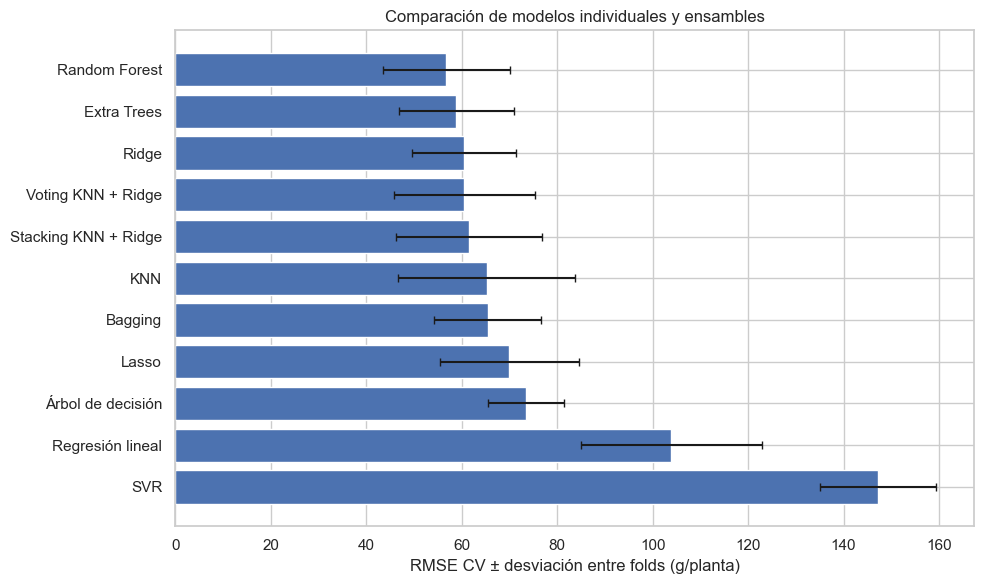

**Interpretación.** El menor RMSE CV corresponde a **Random Forest** (56.76 g/planta). El modelo seleccionado por la regla de estabilidad es **Random Forest**. La dispersión entre folds debe considerarse junto con el promedio por el tamaño reducido de la muestra.

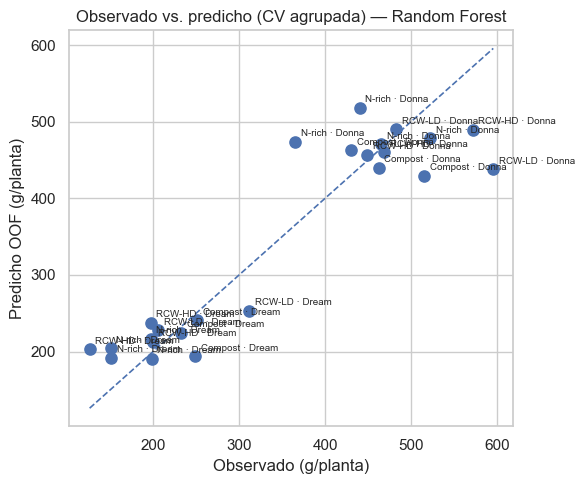

**Interpretación.** Predicciones fuera de fold de **Random Forest**, obtenidas con CV agrupada. Esta visualización no utiliza el conjunto de prueba reutilizado.

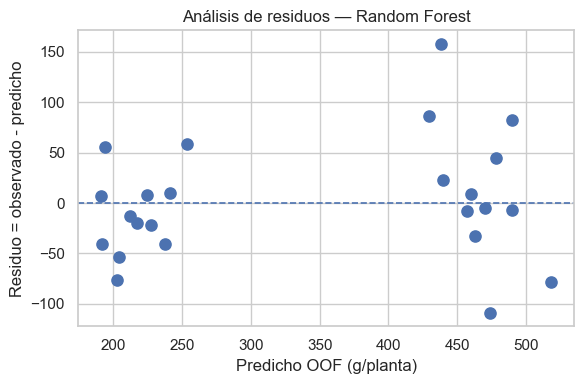

**Interpretación.** El residuo medio es **1.41 g/planta**. Un patrón aleatorio alrededor de cero es deseable; con la muestra reducida de CV no es apropiado afirmar normalidad u homocedasticidad de forma concluyente.

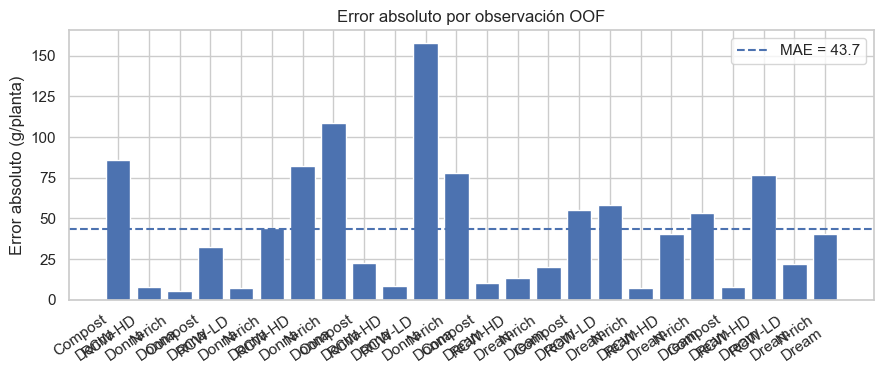

**Interpretación.** El mayor error absoluto ocurre en **RCW-LD · Donna** con 157.74 g/planta. Este caso debe revisarse en contexto antes de atribuirlo a una falla general del modelo.

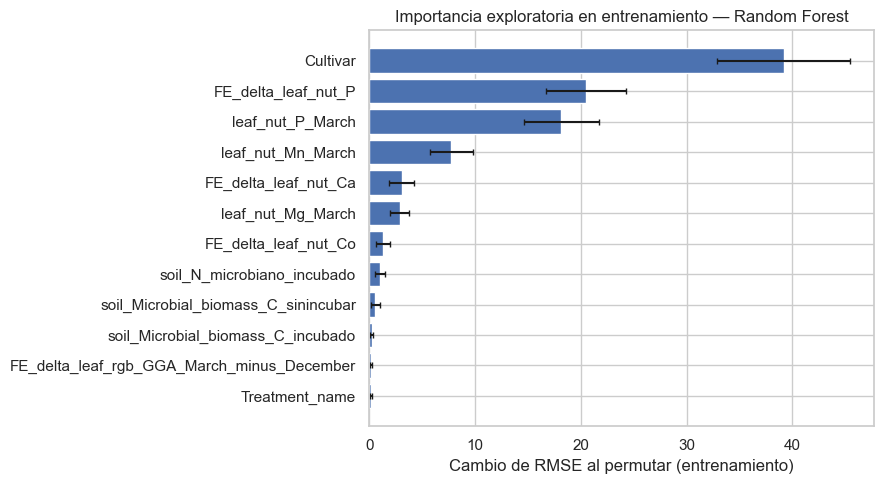

,Variable,Importancia_media,Importancia_sd
65,Cultivar,39.1624,6.2806
50,FE_delta_leaf_nut_P,20.4921,3.7862
26,leaf_nut_P_March,18.1538,3.5399
22,leaf_nut_Mn_March,7.7489,2.0008
38,FE_delta_leaf_nut_Ca,3.0580,1.1748
21,leaf_nut_Mg_March,2.8521,0.9172
40,FE_delta_leaf_nut_Co,1.2705,0.6603
7,soil_N_microbiano_incubado,0.9746,0.4818
4,soil_Microbial_biomass_C_sinincubar,0.5713,0.4096
5,soil_Microbial_biomass_C_incubado,0.2279,0.1514


**Limitación:** esta importancia se estima sobre entrenamiento y puede ser optimista. No es causal ni debe utilizarse para volver a seleccionar características.

In [25]:
# 1) Comparación de todos los modelos.
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(comparison5['Modelo'], comparison5['RMSE_CV'], xerr=comparison5['RMSE_sd'], capsize=3)
ax.invert_yaxis()
ax.set_xlabel('RMSE CV ± desviación entre folds (g/planta)')
ax.set_title('Comparación de modelos individuales y ensambles')
plt.tight_layout(); plt.savefig(OUT5/'01_comparacion_modelos.png', dpi=180); plt.show()

best_abs = comparison5.iloc[0]
display(Markdown(
    f"**Interpretación.** El menor RMSE CV corresponde a **{best_abs['Modelo']}** "
    f"({best_abs['RMSE_CV']:.2f} g/planta). El modelo seleccionado por la regla de estabilidad es "
    f"**{winner}**. La dispersión entre folds debe considerarse junto con el promedio por el tamaño reducido de la muestra."
))

# 2) Observado vs predicho, usando predicciones OOF de validacion agrupada.
# No se consulta el holdout reutilizado para diagnosticar o seleccionar.
plot_data = train_data.reset_index(drop=True)
yt_plot = np.asarray(y, dtype=float)
yhat_plot = np.asarray(oof_predictions[winner], dtype=float)
assert len(yt_plot) == len(yhat_plot) and np.isfinite(yhat_plot).all()

fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(yt_plot, yhat_plot, s=65)
lims=[min(float(yt_plot.min()),float(yhat_plot.min())), max(float(yt_plot.max()),float(yhat_plot.max()))]
ax.plot(lims, lims, '--', linewidth=1.2)
for i,(obs,pred) in enumerate(zip(yt_plot,yhat_plot)):
    label=f"{plot_data.iloc[i]['Treatment_name']} · {plot_data.iloc[i]['Cultivar']}"
    ax.annotate(label, (obs,pred), xytext=(4,4), textcoords='offset points', fontsize=7)
ax.set_xlabel('Observado (g/planta)'); ax.set_ylabel('Predicho OOF (g/planta)')
ax.set_title(f'Observado vs. predicho (CV agrupada) — {winner}')
plt.tight_layout(); plt.savefig(OUT5/'02_observado_predicho.png', dpi=180); plt.show()

display(Markdown(
    f"**Interpretación.** Predicciones fuera de fold de **{winner}**, obtenidas con CV agrupada. "
    "Esta visualización no utiliza el conjunto de prueba reutilizado."
))

# 3) Residuos.
resid = yt_plot - yhat_plot
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(yhat_plot, resid, s=65)
ax.axhline(0, linestyle='--', linewidth=1.2)
ax.set_xlabel('Predicho OOF (g/planta)'); ax.set_ylabel('Residuo = observado - predicho')
ax.set_title(f'Análisis de residuos — {winner}')
plt.tight_layout(); plt.savefig(OUT5/'03_residuos.png', dpi=180); plt.show()

bias=float(np.mean(resid))
display(Markdown(
    f"**Interpretación.** El residuo medio es **{bias:.2f} g/planta**. "
    "Un patrón aleatorio alrededor de cero es deseable; con la muestra reducida de CV no es apropiado afirmar normalidad u homocedasticidad de forma concluyente."
))

# 4) Error absoluto por observación.
labels=[f"{r.Treatment_name}\n{r.Cultivar}" for _,r in plot_data.iterrows()]
abs_error=np.abs(resid)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(np.arange(len(abs_error)), abs_error)
ax.axhline(abs_error.mean(), linestyle='--', label=f'MAE = {abs_error.mean():.1f}')
ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('Error absoluto (g/planta)'); ax.set_title('Error absoluto por observación OOF')
ax.legend(); plt.tight_layout(); plt.savefig(OUT5/'04_error_absoluto.png', dpi=180); plt.show()

worst=int(np.argmax(abs_error))
display(Markdown(
    f"**Interpretación.** El mayor error absoluto ocurre en **{labels[worst].replace(chr(10),' · ')}** "
    f"con {abs_error[worst]:.2f} g/planta. Este caso debe revisarse en contexto antes de atribuirlo a una falla general del modelo."
))

# 5) Importancia por permutacion exploratoria en entrenamiento.
# No se usa para seleccionar el modelo; no es importancia OOF.
imp = permutation_importance(
    final5, X, y, n_repeats=10, random_state=SEED,
    scoring='neg_root_mean_squared_error', n_jobs=1
)
importance = pd.DataFrame({
    'Variable': X.columns,
    'Importancia_media': imp.importances_mean,
    'Importancia_sd': imp.importances_std
}).sort_values('Importancia_media', ascending=False).head(12)

fig, ax = plt.subplots(figsize=(9,5))
show=importance.sort_values('Importancia_media')
ax.barh(show['Variable'], show['Importancia_media'], xerr=show['Importancia_sd'], capsize=2)
ax.set_xlabel('Cambio de RMSE al permutar (entrenamiento)')
ax.set_title(f'Importancia exploratoria en entrenamiento — {winner}')
plt.tight_layout(); plt.savefig(OUT5/'05_importancia_permutacion.png', dpi=180); plt.show()
display(importance.round(4))
display(Markdown(
    '**Limitación:** esta importancia se estima sobre entrenamiento y puede ser optimista. '
    'No es causal ni debe utilizarse para volver a seleccionar características.'
))


## Síntesis metodológica y limitaciones
- **Integración científica:** se conservan suelo, hoja, RGB, producción, calidad fisicoquímica, vitamina C, capacidad antioxidante, polifenoles y antocianinas en la matriz multibloque; cada resultado del fruto se evalúa también como objetivo independiente cuando existe cobertura suficiente.
- **Selección predictiva:** Top 6 y Top 8 son controles de sensibilidad; Top 12, Top 16 y Top 20 preservan los tres bloques predictivos. No se impone una cuota fija antes de la comparación.
- **Interacciones:** se construyen, seleccionan y contrastan contra modelos sin interacciones. Su incorporación depende de la mejora real en validación.
- **Modelos:** se comparan algoritmos individuales y ensambles antes de profundizar en sus configuraciones.
- **Inferencia:** los contrastes entre tratamientos y cultivares son exploratorios; una correlación o una predicción precisa no demuestra causalidad.
- **Campañas:** la comparación integral 2022–2023 requiere fuentes equivalentes y claves de unión verificadas.
- **Evaluación:** la prueba ha sido consultada anteriormente y no constituye validación externa independiente.

**Conclusiones del entregable:** completar únicamente con las métricas obtenidas al ejecutar esta versión. Evitar afirmar mejoras no comprobadas.

In [26]:
# Exportación y controles finales de reproducibilidad.
importance.to_csv(OUT5/'importancia_permutacion.csv', index=False)

checks = pd.DataFrame([
    {'Control':'32 observaciones analíticas', 'Cumple':len(work)==32},
    {'Control':'16 parcelas', 'Cumple':work.Parcel_ID.nunique()==16},
    {'Control':'Sin overlap train/test por parcela', 'Cumple':set(train_data.Parcel_ID).isdisjoint(set(test_data.Parcel_ID))},
    {'Control':'6 modelos individuales incluidos', 'Cumple':sum(comparison5.Estrategia.eq('Individual'))==6},
    {'Control':'Ensambles homogéneos incluidos', 'Cumple':sum(comparison5.Estrategia.eq('Homogéneo'))>=3},
    {'Control':'Ensambles heterogéneos incluidos', 'Cumple':sum(comparison5.Estrategia.eq('Heterogéneo'))>=2},
    {'Control':'Tabla ordenada por RMSE', 'Cumple':comparison5.RMSE_CV.is_monotonic_increasing},
    {'Control':'Tiempo de entrenamiento reportado', 'Cumple':comparison5.Tiempo_entrenamiento_s.notna().all()},
])
display(checks)
checks.to_csv(OUT5/'controles_calidad.csv', index=False)

print('Archivos exportados en:', OUT5)
print('Modelo final:', winner)


,Control,Cumple
0,32 observaciones analíticas,True
1,16 parcelas,True
2,Sin overlap train/test por parcela,True
3,6 modelos individuales incluidos,True
4,Ensambles homogéneos incluidos,True
5,Ensambles heterogéneos incluidos,True
6,Tabla ordenada por RMSE,True
7,Tiempo de entrenamiento reportado,True


Archivos exportados en: C:\Nueva carpeta\Proyecto-Integrador---Equipo-54\outputs\avance5_modelado_integral\ensambles
Modelo final: Random Forest


## Declaración de uso de herramientas de inteligencia artificial

Durante la elaboración de esta libreta, el **Equipo 54**, integrado por **Fanny Betsabé Fuentes Reyes, Juan Luis Ramírez Sánchez y Joaquín Rincón Pérez**, utilizó herramientas de inteligencia artificial generativa como apoyo para la estructuración del flujo analítico, revisión de código, depuración, documentación y discusión metodológica.

Se utilizó **ChatGPT de OpenAI** como apoyo para revisar la arquitectura de la libreta, proponer alternativas de implementación de modelos de ensamble, verificar criterios de validación y mejorar la claridad de las explicaciones. También se utilizó **GitHub Copilot** como apoyo en actividades de edición y gestión del código dentro del repositorio.

Las herramientas de inteligencia artificial **no generaron, modificaron ni sustituyeron los datos experimentales**. Los resultados numéricos mostrados en esta libreta se obtienen mediante la ejecución del código sobre los archivos proporcionados para el proyecto. La selección de métodos, revisión de resultados, interpretación, conclusiones y responsabilidad académica del trabajo corresponden a los integrantes del equipo.

**Referencia de la herramienta principal:** OpenAI. (2026). *ChatGPT* [Modelo de lenguaje de gran escala]. https://chatgpt.com/
